In [147]:
# Let's create a dict with some of the names that refer to the same character
name_corrections = {
    "Bellatrix Lestrange Black": "Bellatrix",
    "Bellatrix Lestrange": "Bellatrix",
    "Sirius Black": "Sirius",
    "Sirius": "Sirius",
    "Albus Dumbledore": "Dumbledore",
    "Albus": "Dumbledore",
    "Minerva McGonagall": "McGonagall",
    "Fleur Delacour": "Fleur",
    "Diggory":"Cedric",
    "Dumbledore":"Dumbledore",
    "Petunia Dursley":"Petunia",
    "Petunia":"Petunia",
    "Petunia Evans":"Petunia",
    "Rubeus Hagrid":"Hagrid",
    "Hagrid":"Hagrid",
    "Rubeus":"Hagrid",
    "Hedwig":"Hedwig",
    "Hedwig the owl":"Hedwig",
    "Krum":"Krum",
    "Viktor Krum":"Krum",
    "Viktor":"Krum",
    "Victor":"Krum",
    "Loopy Lupin Loony":"Lupin",
    "Remus Lupin":"Lupin",
    "Lupin":"Lupin",
    "Remus":"Lupin",
    "Loony Lupin":"Lupin",
    "Loony":"Lupin",
    "Dora Nymphadora Tonks":"Tonks",
    "Nymphadora Tonks":"Tonks",
    "Tonks":"Tonks",
    "Nymphadora":"Tonks",
    "Dora Nymphadora Tonks Lupin":"Tonks",
    "Remus J. Lupin":"Lupin",
    "M. G. McGonagall":"McGonagall",
    "Moaning Myrtle":"Moaning Myrtle",
    "Mad Moody":"Mad Moody",
    "Alastor Moody":"Mad Moody",
    "Alastor 'Mad-Eye' Moody":"Mad Moody",
    "Alastor 'Mad Eye' Moody":"Mad Moody",
    "Alastor": "Mad Moody",
    "Moony": "Lupin",
    "Padfoot": "Sirius",
    "Prongs": "James",
    "James Potter": "James",
    "James": "James",
    "Myrtle": "Moaning Myrtle",
    "Boy Who Lived": "Harry",
    "The chosen one": "Harry",
    "Harry Potter": "Harry",
    "Harry": "Harry",
    "Tom Riddle": "Voldemort",
    "Marvolo": "Voldemort",
    "Lord Voldemort": "Voldemort",
    "Voldemort": "Voldemort",
    "He-Who-Must-Not-Be-Named": "Voldemort",
    "You-Know-Who": "Voldemort",
    "Tom Marvolo Riddle": "Voldemort",
    "Riddle": "Voldemort",
    "Tom": "Voldemort",
    "Dark Lord": "Voldemort",
    "Severus Snape": "Snape",
    "Snape": "Snape",
    "Severus": "Snape",
    "Dolores Umbridge": "Umbridge",
    "Umbridge": "Umbridge",
    "Dolores": "Umbridge",
    "Dolores Jane Umbridge": "Umbridge",
    "Ronald Weasley": "Ron",
    "Ron Weasley": "Ron",
    "Ron": "Ron",
    "Ronald": "Ron",
    "Fleur Delacour-Weasley": "Fleur",
    "Fleur Delacour Weasley": "Fleur",
    "Fleur": "Fleur",
    "Hermione Granger": "Hermione",
    "Hermione": "Hermione",
    "Granger": "Hermione",
    "Hermione Jean Granger": "Hermione",
    "Hermione J. Granger": "Hermione",
    "Hermione Granger-Weasley": "Hermione",
    "Hermione Granger Weasley": "Hermione",
    "Wormtail": "Wormtail",
    "Peter Pettigrew": "Wormtail",
    "Pettigrew": "Wormtail",
    "Peter": "Wormtail",
    "Victor Krum": "Krum",
    "Mr. Dursley": "Mr. Dursley",
    "Mrs. Dursley": "Mrs. Dursley",
    "Lovegood": "Luna",
    "Gilbert Wimple": "Wimple"
}


In [148]:
import pandas as pd
from itertools import combinations
import os
import re

class LinkGenerator:
    def __init__(self, books_dir, df_characters, name_corrections):
        self.books_dir = books_dir
        self.df_characters = df_characters.copy()
        self.name_corrections = name_corrections

        self.book_files = self._get_book_files()
        self.books_lines = self._load_books()

        # Precompile regex patterns for raw character names
        self.character_patterns = {
            name: re.compile(rf"\b{re.escape(name)}\b")
            for name in df_characters["name"]
        }

        # Precompile regex patterns for the corrections as well
        # (there may be names not in df_characters)
        self.correction_patterns = {
            raw_name: re.compile(rf"\b{re.escape(raw_name)}\b")
            for raw_name in name_corrections.keys()
        }
    
    def _apply_corrections(self, detected_names, line):
        """
        Given the raw detected names, map them to canonical ones using name_corrections.
        Also detect corrected names directly from the line.
        """
        corrected = []

        # 1. Correct the ones found in df_characters
        for n in detected_names:
            corrected.append(self.name_corrections.get(n, n))

        # 2. Also detect names that appear only in name_corrections
        #    (e.g., "Albus" even if df_chars contains only "Albus Dumbledore")
        for raw_name, pattern in self.correction_patterns.items():
            if pattern.search(line):
                corrected.append(self.name_corrections[raw_name])

        return list(set(corrected))  # remove duplicates
    
    def _get_book_files(self):
        files = [os.path.join(self.books_dir, f) for f in os.listdir(self.books_dir) if f.endswith('.txt')]
        files.sort()
        return files
    
    def _load_books(self):
        books_lines = []
        chapter_pattern = re.compile(r"^\s*CHAPTER\s+[\w\- ]+", re.IGNORECASE)

        for book_id, file_path in enumerate(self.book_files, start=1):
            chapter_number = 1
            with open(file_path, 'r', encoding='utf-8') as f:
                for line_idx, line in enumerate(f, start=1):
                    line_clean = line.strip()
                    if not line_clean:
                        continue

                    if chapter_pattern.match(line_clean):
                        if line_idx != 1:
                            chapter_number += 1

                    books_lines.append((book_id, line_idx, line_clean, chapter_number))

        return books_lines
    
    def _detect_characters_in_line(self, line):
        """
        Detect raw names, then apply canonical corrections.
        """
        raw_matches = []
        for name, pattern in self.character_patterns.items():
            if pattern.search(line):
                raw_matches.append(name)

        # Apply corrections
        corrected = self._apply_corrections(raw_matches, line)
        return corrected
    
    def _valid_pair(self, c1, c2):
        c1_words = set(c1.split())
        c2_words = set(c2.split())
        return not (c1_words & c2_words)
    
    def generate_link_data(self, window_size=3):
        records = []
        n_lines = len(self.books_lines)
    
        seen_pairs = set()
        seen_single = set()
    
        for i in range(n_lines):
            # Rango de la ventana centrada en la línea i
            start_idx = max(0, i - window_size // 2)
            end_idx = min(n_lines, i + window_size // 2 + 1)
            window_lines = self.books_lines[start_idx:end_idx]
    
            # Detectar todos los personajes en la ventana
            chars_in_window = set()
            chapters_in_window = set()
            books_in_window = set()
            line_texts = []
    
            for book_id, line_idx, line, chapter in window_lines:
                line_texts.append(line)
                chapters_in_window.add(chapter)
                books_in_window.add(book_id)
                chars_in_window.update(self._detect_characters_in_line(line))
    
            central_line_idx = window_lines[window_size//2][1]
            book_id = min(books_in_window)
            chapter = min(chapters_in_window)
            combined_line = " ".join(line_texts)
    
            # Apariciones individuales
            for char in chars_in_window:
                key = (char, book_id, chapter, central_line_idx)
                if key not in seen_single:
                    records.append({
                        "character1": char,
                        "character2": None,
                        "line": combined_line,
                        "book": book_id,
                        "chapter": chapter,
                        "line_index": central_line_idx
                    })
                    seen_single.add(key)
    
            # Co-ocurrencias
            for c1, c2 in combinations(sorted(chars_in_window), 2):
                if not self._valid_pair(c1, c2):
                    continue
                key = (c1, c2, book_id, chapter)
                if key not in seen_pairs:
                    records.append({
                        "character1": c1,
                        "character2": c2,
                        "line": combined_line,
                        "book": book_id,
                        "chapter": chapter,
                        "line_index": central_line_idx
                    })
                    seen_pairs.add(key)
    
        return pd.DataFrame(records)

In [149]:
df = pd.read_csv("../data/processed/characters_final_3.csv")

In [150]:
import pandas as pd

# Suppose df_characters is already loaded

# Initialize the generator
generator = LinkGenerator('../data/raw/archive', df, name_corrections)

# Generate co-occurrence graph
df_links = generator.generate_link_data()


In [151]:
import networkx as nx
import pandas as pd

class GraphGenerator:
    def __init__(self, df_links):
        """
        Initialize with a DataFrame containing character co-occurrence links.
        
        Parameters:
        - df_links: pandas DataFrame with columns ['character1', 'character2', 'book', ...]
        """
        self.df_links = df_links
        self.book_graphs, self.global_graph = self._generate_graphs()
    
    def _generate_graphs(self):
        """
        Generates accumulative weighted graphs:
        - graphs[1] = Book 1
        - graphs[2] = Books 1+2
        - ...
        - graphs[N] = global graph

        Returns:
        - dict: {book_id: networkx.Graph (accumulative)}
        - networkx.Graph: global graph
        """
        graphs = {}
        global_G = nx.Graph()

        books = sorted(self.df_links['book'].unique())

        # Start with an empty graph that will accumulate edges
        cumulative_G = nx.Graph()

        for book_id in books:
            df_book = self.df_links[self.df_links['book'] == book_id]

            for _, row in df_book.iterrows():
                char1 = row['character1']
                char2 = row['character2']

                # Nodes with no pair → add node only
                if pd.isna(char2) or char2 is None:
                    cumulative_G.add_node(char1)
                    global_G.add_node(char1)
                    continue

                # Add/update edge in cumulative graph
                if cumulative_G.has_edge(char1, char2):
                    cumulative_G[char1][char2]['weight'] += 1
                else:
                    cumulative_G.add_edge(char1, char2, weight=1)

                # Add/update edge in global graph
                if global_G.has_edge(char1, char2):
                    global_G[char1][char2]['weight'] += 1
                else:
                    global_G.add_edge(char1, char2, weight=1)

            # Save a COPY of cumulative state for this book
            graphs[book_id] = cumulative_G.copy()

        return graphs, global_G

    
    def get_graph(self, book_id):
        """Returns the networkx graph for a specific book_id."""
        return self.book_graphs.get(book_id)
    
    def get_all_graphs(self):
        """Returns the dictionary of all book graphs."""
        return self.book_graphs
    
    def get_global_graph(self):
        """Returns the combined global graph (all books)."""
        return self.global_graph

In [152]:
graph_gen = GraphGenerator(df_links)

# Access all graphs
all_graphs = graph_gen.get_all_graphs()

In [153]:
G_global = graph_gen.get_global_graph()
# and optionally:
# G_book_i = graph_gen.get_graph(i)


In [154]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from collections import Counter

# Louvain (python-louvain package)
try:
    import community as community_louvain
except ImportError:
    community_louvain = None
    print("WARNING: python-louvain not installed. Run `pip install python-louvain` if you want Louvain.")
    

# --------- Helpers to go between formats ---------

def partition_from_dict(partition_dict):
    """
    Convert a dict node -> community_id into a list of sets of nodes.
    """
    comm_map = {}
    for node, cid in partition_dict.items():
        comm_map.setdefault(cid, set()).add(node)
    return list(comm_map.values())


def describe_partition(G, partition, name=""):
    """
    Print some basic information about a (non-overlapping) community partition.
    partition: list[set(nodes)]
    """
    sizes = sorted([len(c) for c in partition], reverse=True)
    print(f"\n=== {name} ===")
    print(f"Number of communities: {len(partition)}")
    print(f"Community sizes (top 10): {sizes[:10]}")
    try:
        mod = nx.community.modularity(G, partition)
        print(f"Modularity: {mod:.4f}")
    except Exception as e:
        print(f"Could not compute modularity: {e}")


def draw_partition(G, partition, title="", pos=None, figsize=(12, 12)):
    """
    Visualize a non-overlapping community partition using NetworkX.
    partition: list[set(nodes)]
    """
    # assign each node a community id
    node2comm = {}
    for cid, comm in enumerate(partition):
        for n in comm:
            node2comm[n] = cid

    # color map
    cmap = plt.cm.get_cmap("tab20")
    colors = []
    for n in G.nodes():
        cid = node2comm.get(n, -1)
        if cid == -1:
            colors.append((0.5, 0.5, 0.5, 1.0))  # gray if missing
        else:
            colors.append(cmap(cid % 20))

    if pos is None:
        pos = nx.spring_layout(G, seed=42)

    plt.figure(figsize=figsize)
    nx.draw_networkx_edges(G, pos, alpha=0.2)
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=80)
    nx.draw_networkx_labels(G, pos, font_size=7)
    plt.title(title)
    plt.axis("off")
    plt.show()


In [155]:
def louvain_communities(G):
    """
    Run Louvain community detection (non-overlapping).
    Returns: list[set(nodes)]
    """
    if community_louvain is None:
        raise ImportError("python-louvain not installed. Run `pip install python-louvain`.")
        
    partition_dict = community_louvain.best_partition(G, weight="weight")
    partition = partition_from_dict(partition_dict)
    return partition


In [156]:
def greedy_communities(G):
    """
    Greedy modularity maximization using NetworkX.
    Returns: list[set(nodes)]
    """
    comms = list(nx.community.greedy_modularity_communities(G, weight="weight"))
    return [set(c) for c in comms]


In [157]:
def girvan_newman_best(G, max_levels=5):
    """
    Girvan–Newman divisive community detection.
    Stops after `max_levels` splits and returns the partition with highest modularity.
    WARNING: can be slow on large graphs.
    """
    comp_gen = nx.community.girvan_newman(G)
    best_mod = -1.0
    best_part = None

    for level, communities in enumerate(comp_gen):
        if level >= max_levels:
            break
        partition = [set(c) for c in communities]
        try:
            mod = nx.community.modularity(G, partition)
        except Exception:
            mod = -1.0
        if mod > best_mod:
            best_mod = mod
            best_part = partition

    return best_part


In [158]:
def cpm_overlapping_communities(G, k=3):
    """
    Clique Percolation Method (CPM) for overlapping communities.
    k: size of cliques (e.g. k=3 triangles, k=4 4-cliques).
    Returns:
        communities: list[set(nodes)]
        cliques: list[set(nodes)]  (all cliques of size >= k)
    """
    # 1. Find all cliques of size >= k
    cliques = [set(c) for c in nx.find_cliques(G) if len(c) >= k]
    if not cliques:
        return [], []

    # 2. Build clique graph: nodes = cliques, edges if they share at least k-1 nodes
    C = nx.Graph()
    for i, c1 in enumerate(cliques):
        C.add_node(i)
    for i in range(len(cliques)):
        for j in range(i + 1, len(cliques)):
            if len(cliques[i] & cliques[j]) >= k - 1:
                C.add_edge(i, j)

    # 3. Connected components of clique graph → communities
    communities = []
    for comp in nx.connected_components(C):
        nodes = set()
        for clique_idx in comp:
            nodes |= cliques[clique_idx]
        communities.append(nodes)

    return communities, cliques


def describe_overlapping_communities(communities, name="Overlapping"):
    sizes = sorted([len(c) for c in communities], reverse=True)
    print(f"\n=== {name} (overlapping) ===")
    print(f"Number of communities: {len(communities)}")
    print(f"Community sizes (top 10): {sizes[:10]}")


In [159]:
def draw_overlapping_communities(G, communities, title="", pos=None, figsize=(12, 12)):
    """
    Visualize overlapping communities:
    - primary community gives node color
    - nodes in >1 community get black border and larger size
    """
    # node -> list of community ids
    membership = {n: [] for n in G.nodes()}
    for cid, comm in enumerate(communities):
        for n in comm:
            membership.setdefault(n, []).append(cid)

    cmap = plt.cm.get_cmap("tab20")
    node_colors = []
    node_sizes = []
    node_edgecolors = []

    for n in G.nodes():
        cids = membership.get(n, [])
        if not cids:
            node_colors.append((0.7, 0.7, 0.7, 1.0))
            node_sizes.append(80)
            node_edgecolors.append("none")
        else:
            main_cid = cids[0]
            node_colors.append(cmap(main_cid % 20))
            if len(cids) > 1:
                node_sizes.append(180)
                node_edgecolors.append("black")
            else:
                node_sizes.append(120)
                node_edgecolors.append("none")

    if pos is None:
        pos = nx.spring_layout(G, seed=42)

    plt.figure(figsize=figsize)
    nx.draw_networkx_edges(G, pos, alpha=0.2)
    nx.draw_networkx_nodes(
        G,
        pos,
        node_color=node_colors,
        node_size=node_sizes,
        edgecolors=node_edgecolors,
        linewidths=1.5,
    )
    nx.draw_networkx_labels(G, pos, font_size=7)
    plt.title(title)
    plt.axis("off")
    plt.show()


In [160]:
def get_degrees(G):
    """
    Return degree sequence as a numpy array.
    (Unweighted degrees; if you want weighted, use degree(weight='weight').)
    """
    return np.array([d for _, d in G.degree()], dtype=float)


def estimate_gamma_mle(degrees, k_min=1):
    """
    Estimate power-law exponent gamma for degrees >= k_min
    using an approximate MLE for discrete data:
        gamma_hat = 1 + n / sum(log(k / (k_min - 0.5)))
    (See Clauset, Shalizi, Newman 2009)
    """
    degrees = np.array(degrees, dtype=float)
    ks = degrees[degrees >= k_min]
    n = len(ks)
    if n == 0:
        raise ValueError("No degrees >= k_min. Choose smaller k_min.")

    # Avoid division by zero when k_min=1
    shift = k_min - 0.5 if k_min > 1 else 0.5
    gamma_hat = 1.0 + n / np.sum(np.log(ks / shift))
    return gamma_hat


def plot_degree_distribution_with_fit(G, k_min=3, bins=20):
    """
    Plot CCDF of the degree distribution on log–log scale
    and print gamma estimate.
    """
    degrees = get_degrees(G)
    gamma_hat = estimate_gamma_mle(degrees, k_min=k_min)
    print(f"Estimated gamma (k_min={k_min}): {gamma_hat:.3f}")

    # CCDF
    k_vals = np.array(sorted(degrees))
    counts = Counter(k_vals)
    ks = np.array(sorted(counts.keys()))
    pk = np.array([counts[k] for k in ks], dtype=float) / len(degrees)
    ccdf = 1.0 - np.cumsum(pk)

    # Only plot region k >= k_min
    mask = ks >= k_min
    ks_plot = ks[mask]
    ccdf_plot = ccdf[mask]

    plt.figure(figsize=(7, 5))
    plt.loglog(ks_plot, ccdf_plot, "o", label="data CCDF")

    # Simple straight-line reference using estimated gamma:
    # For a power law, CCDF ~ k^{1-gamma}
    # We'll fit a line anchored at k_min.
    if len(ks_plot) > 0:
        x_ref = np.array([ks_plot[0], ks_plot[-1]], dtype=float)
        y_ref = (x_ref / x_ref[0]) ** (1 - gamma_hat) * ccdf_plot[0]
        plt.loglog(x_ref, y_ref, "--", label=f"fit γ={gamma_hat:.2f}")

    plt.xlabel("Degree k")
    plt.ylabel("P(K ≥ k)")
    plt.title("Degree CCDF with power-law fit")
    plt.legend()
    plt.grid(True, which="both", alpha=0.3)
    plt.show()



=== Louvain (global HP) ===
Number of communities: 8
Community sizes (top 10): [125, 122, 67, 50, 45, 19, 6, 6]
Modularity: 0.1232


/var/folders/7b/gg3rf9zj28bfyjwgyw4z4xhw0000gq/T/ipykernel_9920/4088690958.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20")


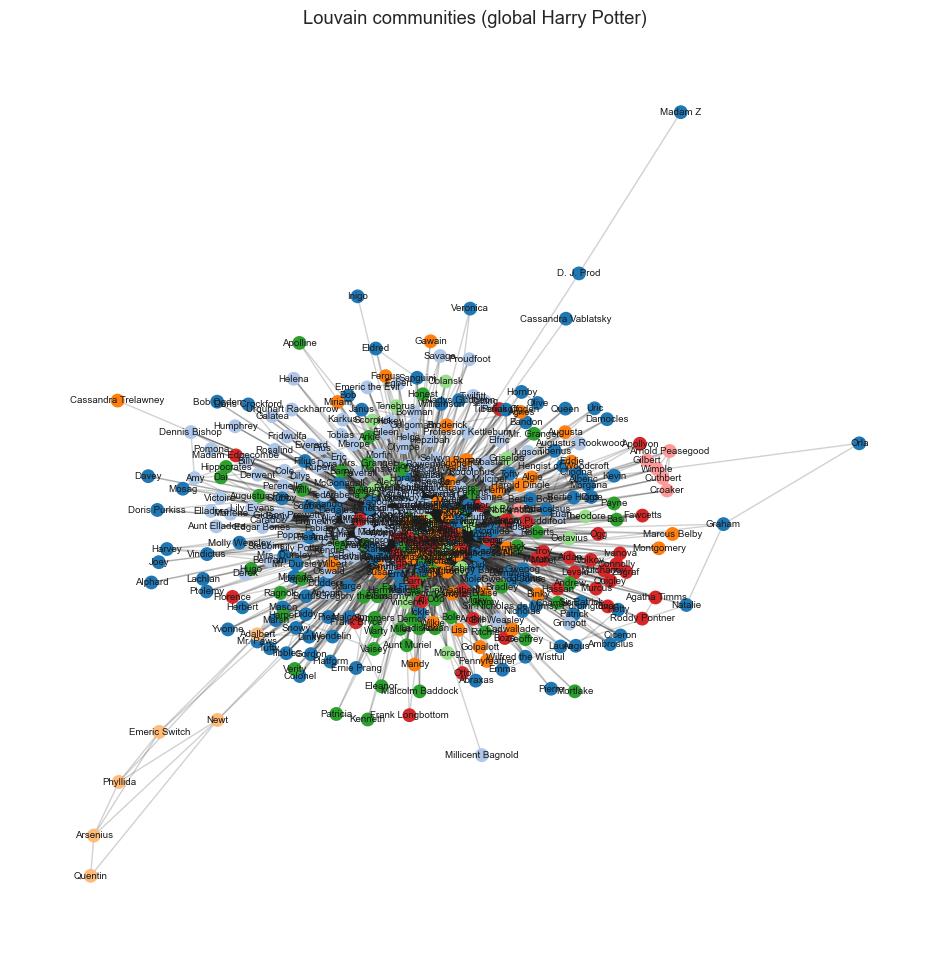


=== Greedy modularity (global HP) ===
Number of communities: 9
Community sizes (top 10): [131, 127, 110, 51, 6, 5, 5, 3, 2]
Modularity: 0.1268


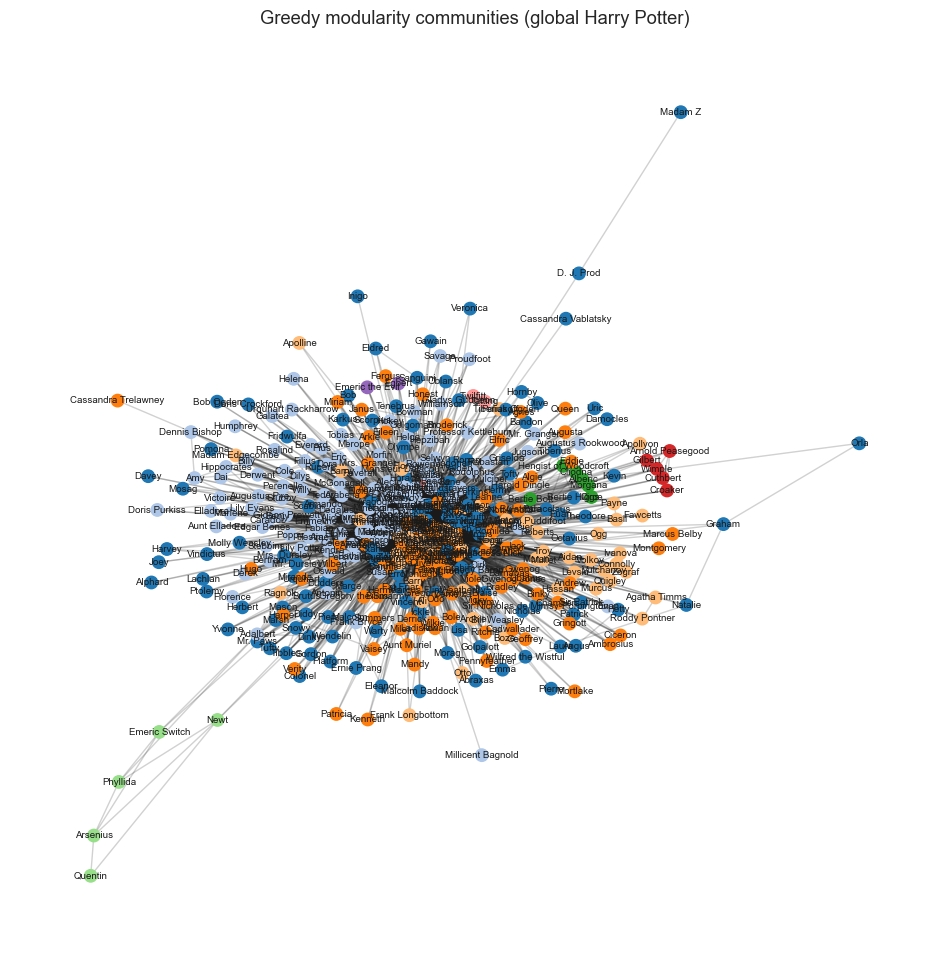


=== Girvan–Newman (high-degree subgraph) ===
Number of communities: 4
Community sizes (top 10): [220, 11, 7, 1]
Modularity: 0.0060


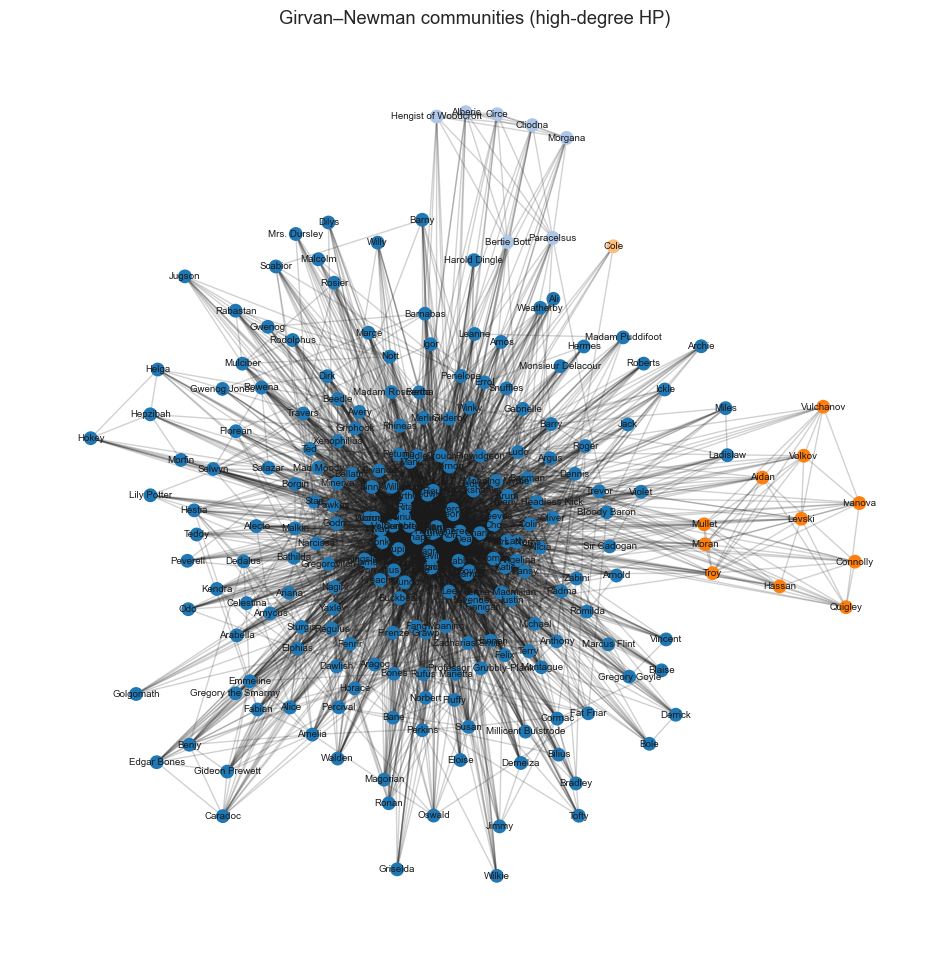

In [161]:
# Use your existing generator
# G_global = graph_gen.get_global_graph()
G = G_global

# One layout reused across plots (so they are comparable)
pos = nx.spring_layout(G, seed=42)

# ---------- Non-overlapping: Louvain ----------
louvain_part = louvain_communities(G)
describe_partition(G, louvain_part, name="Louvain (global HP)")
draw_partition(G, louvain_part, title="Louvain communities (global Harry Potter)", pos=pos)

# ---------- Non-overlapping: Greedy modularity ----------
greedy_part = greedy_communities(G)
describe_partition(G, greedy_part, name="Greedy modularity (global HP)")
draw_partition(G, greedy_part, title="Greedy modularity communities (global Harry Potter)", pos=pos)

# ---------- Optional: Girvan–Newman on a smaller subgraph ----------
# For example: induced subgraph of nodes with degree >= 10
high_deg_nodes = [n for n, d in G.degree() if d >= 10]
G_high = G.subgraph(high_deg_nodes).copy()

gn_part = girvan_newman_best(G_high, max_levels=5)
describe_partition(G_high, gn_part, name="Girvan–Newman (high-degree subgraph)")
draw_partition(G_high, gn_part, title="Girvan–Newman communities (high-degree HP)", pos=None)



=== CPM k=3 (global HP) (overlapping) ===
Number of communities: 1
Community sizes (top 10): [433]


/var/folders/7b/gg3rf9zj28bfyjwgyw4z4xhw0000gq/T/ipykernel_9920/3774216441.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20")


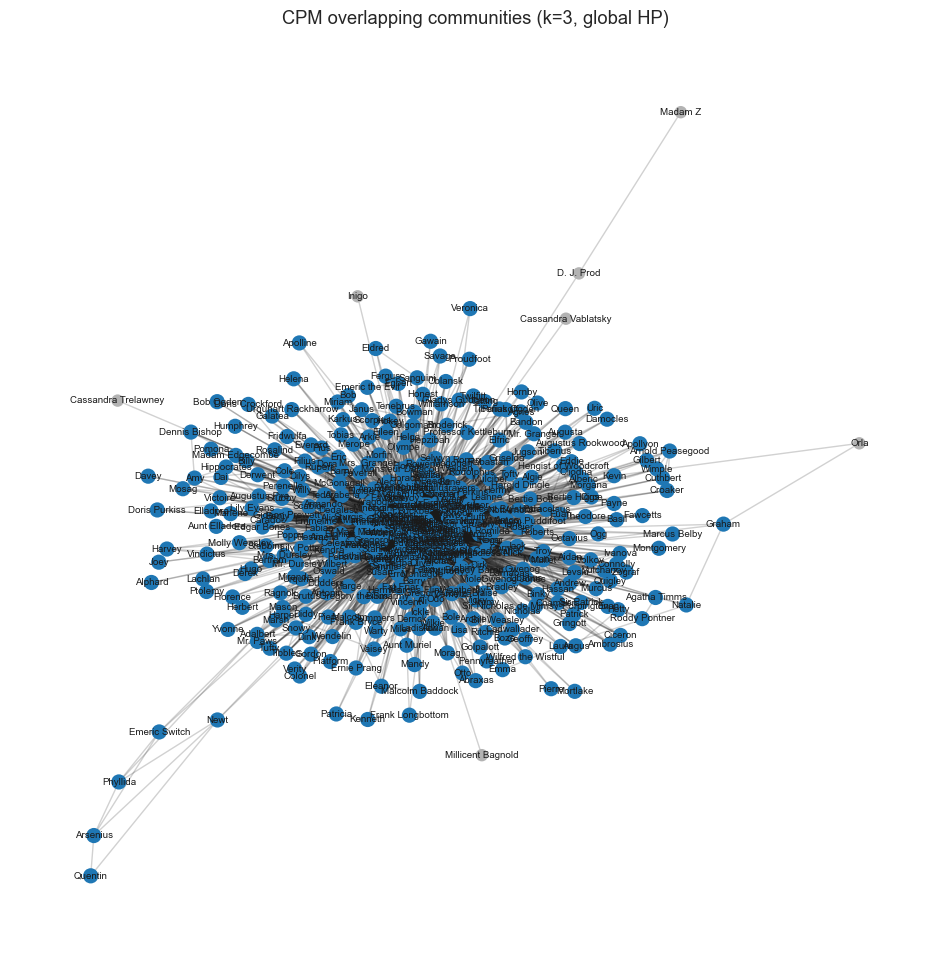

In [162]:
# ---------- Overlapping: CPM with k=3 (triangles) ----------
cpm_comms, cpm_cliques = cpm_overlapping_communities(G, k=3)
describe_overlapping_communities(cpm_comms, name="CPM k=3 (global HP)")
draw_overlapping_communities(G, cpm_comms, title="CPM overlapping communities (k=3, global HP)", pos=pos)


Estimated gamma (k_min=18): 2.102


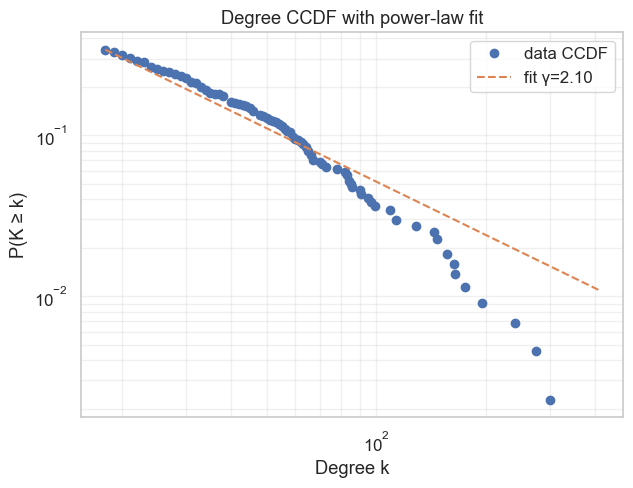

In [163]:
# ---------- Gamma estimation ----------
plot_degree_distribution_with_fit(G, k_min=18)




########## BOOK 1 ##########

=== Louvain (Book 1) ===
Number of communities: 8
Community sizes (top 10): [32, 26, 22, 14, 8, 8, 5, 1]
Modularity: 0.2531
Estimated gamma (k_min=18): 2.860


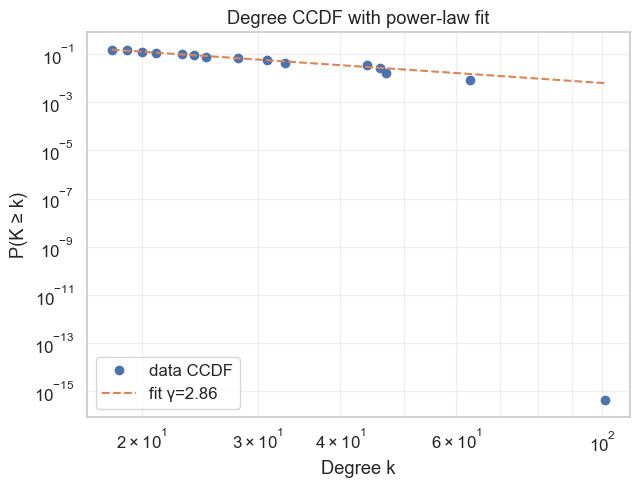



########## BOOK 2 ##########

=== Louvain (Book 2) ===
Number of communities: 9
Community sizes (top 10): [41, 38, 29, 16, 10, 8, 8, 3, 1]
Modularity: 0.1823
Estimated gamma (k_min=18): 2.524


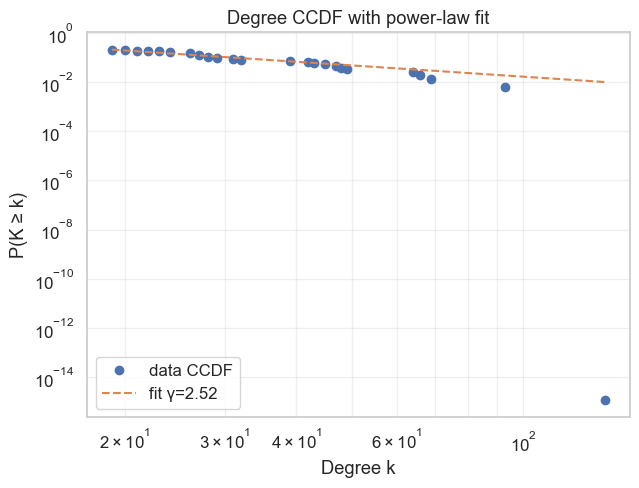



########## BOOK 3 ##########

=== Louvain (Book 3) ===
Number of communities: 7
Community sizes (top 10): [44, 36, 35, 24, 22, 13, 8]
Modularity: 0.1659
Estimated gamma (k_min=18): 2.450


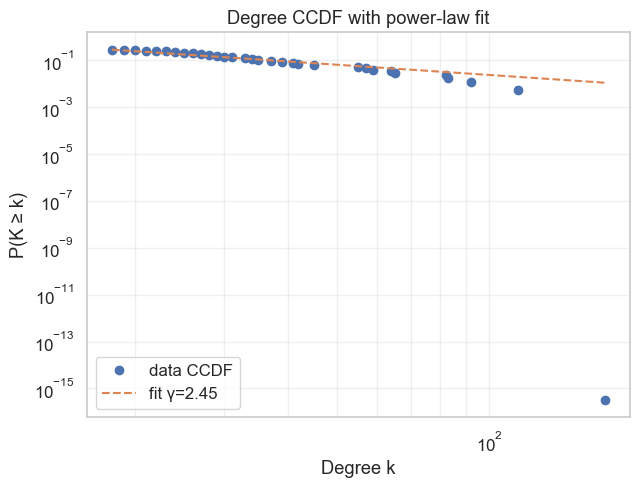



########## BOOK 4 ##########

=== Louvain (Book 4) ===
Number of communities: 8
Community sizes (top 10): [80, 56, 50, 47, 14, 8, 8, 6]
Modularity: 0.1574
Estimated gamma (k_min=18): 2.246


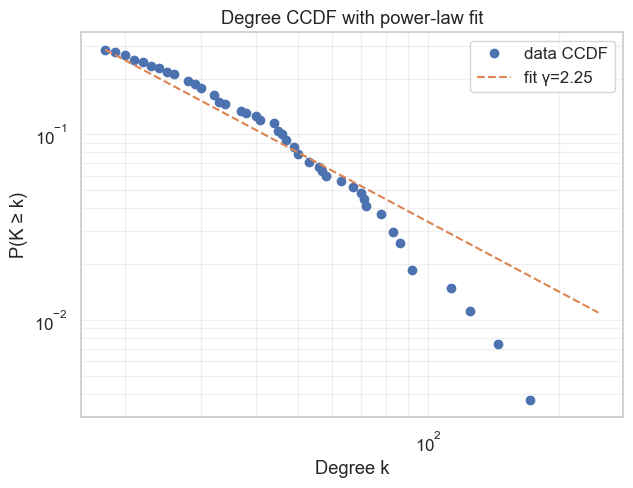



########## BOOK 5 ##########

=== Louvain (Book 5) ===
Number of communities: 7
Community sizes (top 10): [95, 95, 64, 46, 42, 7, 6]
Modularity: 0.1479
Estimated gamma (k_min=18): 2.125


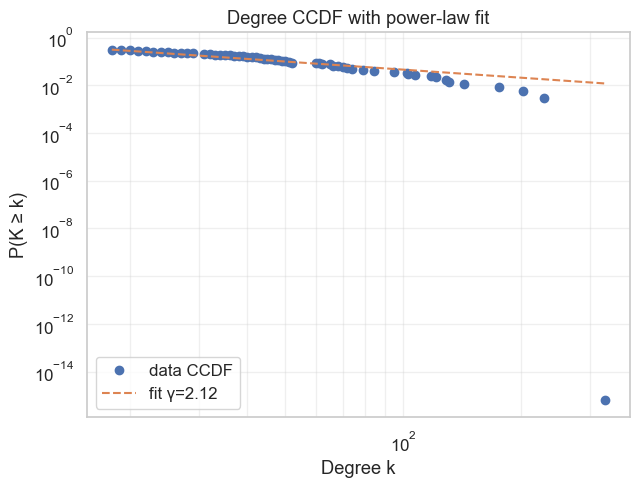



########## BOOK 6 ##########

=== Louvain (Book 6) ===
Number of communities: 7
Community sizes (top 10): [128, 116, 97, 44, 21, 7, 5]
Modularity: 0.1359
Estimated gamma (k_min=18): 2.084


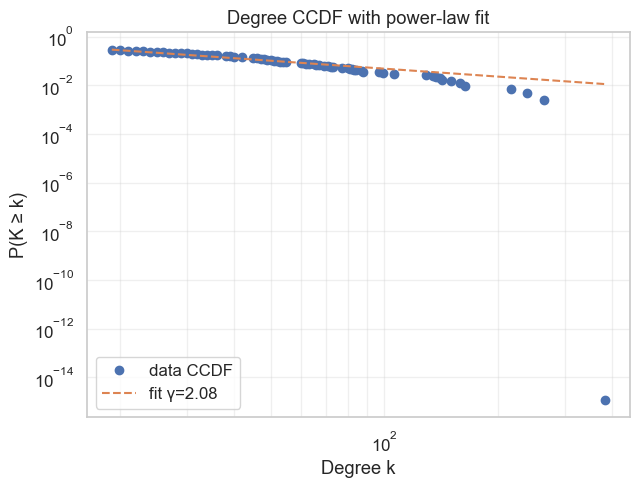



########## BOOK 7 ##########

=== Louvain (Book 7) ===
Number of communities: 9
Community sizes (top 10): [126, 122, 105, 46, 17, 7, 7, 5, 5]
Modularity: 0.1253
Estimated gamma (k_min=18): 2.102


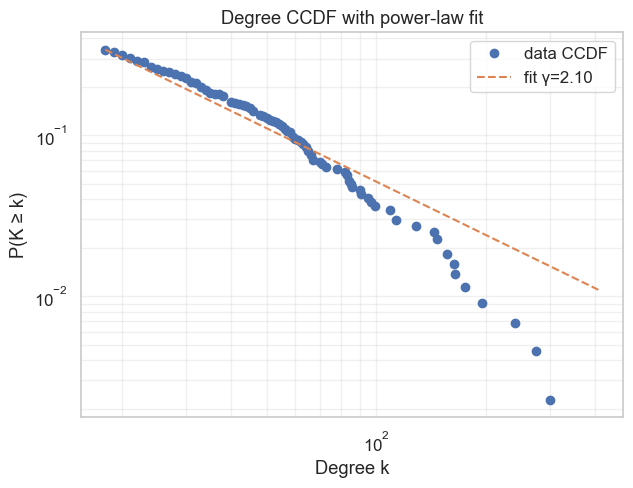

In [164]:
for book_id in range(1, 8):
    G_book = graph_gen.get_graph(book_id)
    print(f"\n\n########## BOOK {book_id} ##########")

    # Community detection
    louvain_part_b = louvain_communities(G_book)
    describe_partition(G_book, louvain_part_b, name=f"Louvain (Book {book_id})")

    # Gamma per book
    plot_degree_distribution_with_fit(G_book, k_min=18)


In [165]:
def community_metrics(G, partition):
    """
    Compute basic metrics per community:
    - size
    - number of internal edges
    - internal density
    - avg internal degree
    - avg external degree
    Returns: pandas.DataFrame
    """
    rows = []
    # Build node -> community id map
    node2comm = {}
    for cid, comm in enumerate(partition):
        for n in comm:
            node2comm[n] = cid

    for cid, comm in enumerate(partition):
        comm = set(comm)
        subG = G.subgraph(comm)
        size = len(comm)
        internal_edges = subG.number_of_edges()
        # possible edges for undirected simple graph
        possible_edges = size * (size - 1) / 2 if size > 1 else 0
        density = internal_edges / possible_edges if possible_edges > 0 else 0.0

        k_int_list = []
        k_ext_list = []
        for n in comm:
            neighbors = set(G.neighbors(n))
            k_int = len(neighbors & comm)
            k_ext = len(neighbors - comm)
            k_int_list.append(k_int)
            k_ext_list.append(k_ext)

        avg_k_int = float(np.mean(k_int_list)) if k_int_list else 0.0
        avg_k_ext = float(np.mean(k_ext_list)) if k_ext_list else 0.0

        rows.append({
            "community_id": cid,
            "size": size,
            "internal_edges": internal_edges,
            "density": density,
            "avg_internal_degree": avg_k_int,
            "avg_external_degree": avg_k_ext,
        })

    return pd.DataFrame(rows).sort_values(by="size", ascending=False)


In [166]:
comm_df = community_metrics(G, louvain_part)
comm_df.head()


,community_id,size,internal_edges,density,avg_internal_degree,avg_external_degree
1,1,125,929,0.119871,14.864000,14.048000
0,0,122,407,0.055142,6.672131,10.418033
4,4,67,327,0.147897,9.761194,20.119403
2,2,50,242,0.197551,9.680000,22.020000
6,6,45,180,0.181818,8.000000,14.200000


In [167]:
print(comm_df.to_latex(index=False, float_format="%.3f"))


\begin{tabular}{rrrrrr}
\toprule
community_id & size & internal_edges & density & avg_internal_degree & avg_external_degree \\
\midrule
1 & 125 & 929 & 0.120 & 14.864 & 14.048 \\
0 & 122 & 407 & 0.055 & 6.672 & 10.418 \\
4 & 67 & 327 & 0.148 & 9.761 & 20.119 \\
2 & 50 & 242 & 0.198 & 9.680 & 22.020 \\
6 & 45 & 180 & 0.182 & 8.000 & 14.200 \\
5 & 19 & 49 & 0.287 & 5.158 & 22.211 \\
3 & 6 & 9 & 0.600 & 3.000 & 1.667 \\
7 & 6 & 14 & 0.933 & 4.667 & 4.500 \\
\bottomrule
\end{tabular}



In [168]:
def node_roles(G, partition, hub_quantile=0.9):
    """
    Classify nodes into roles:
    - 'hub': high-degree nodes touching >= 2 communities
    - 'bridge': k_ext > k_int (more links outside than inside)
    - 'internal': k_int >= k_ext and not hub
    Returns: pandas.DataFrame with one row per node.
    """
    # node -> community id
    node2comm = {}
    for cid, comm in enumerate(partition):
        for n in comm:
            node2comm[n] = cid

    degrees = dict(G.degree())
    all_deg = np.array(list(degrees.values()), dtype=float)
    deg_threshold = np.quantile(all_deg, hub_quantile)

    rows = []

    for n in G.nodes():
        c = node2comm.get(n, None)
        neighbors = list(G.neighbors(n))
        k = degrees[n]

        # community membership(s)
        comm_neighbors = [node2comm.get(v, None) for v in neighbors]
        same_comm = [v for v in neighbors if node2comm.get(v, None) == c]
        other_comm = [v for v in neighbors if node2comm.get(v, None) != c]

        k_int = len(same_comm)
        k_ext = len(other_comm)

        # How many distinct communities this node touches?
        comms_touched = set([cc for cc in comm_neighbors if cc is not None])
        num_comms_touched = len(comms_touched)

        role = "internal"  # default

        # hub: very high degree AND touches at least 2 communities
        if (k >= deg_threshold) and (num_comms_touched >= 2):
            role = "hub"
        # bridge: not hub, more external links than internal
        elif k_ext > k_int:
            role = "bridge"
        else:
            role = "internal"

        rows.append({
            "node": n,
            "community_id": c,
            "degree": k,
            "k_internal": k_int,
            "k_external": k_ext,
            "num_communities_touched": num_comms_touched,
            "role": role,
        })

    df = pd.DataFrame(rows)
    # sort: hubs first, then bridges, then internal, then by degree
    role_order = {"hub": 0, "bridge": 1, "internal": 2}
    df["role_rank"] = df["role"].map(role_order)
    df = df.sort_values(by=["role_rank", "degree"], ascending=[True, False]).drop(columns=["role_rank"])
    return df


In [169]:
roles_df = node_roles(G, louvain_part, hub_quantile=0.9)
roles_df.head(20)


,node,community_id,degree,k_internal,k_external,num_communities_touched,role
3,Harry,0,408,117,291,8,hub
51,Ron,4,301,55,246,7,hub
63,Hermione,1,275,89,186,7,hub
8,Dumbledore,1,240,98,142,7,hub
5,Voldemort,1,195,96,99,6,hub
12,Hagrid,1,175,68,107,7,hub
52,Neville,2,165,32,133,6,hub
48,Ginny,4,164,34,130,7,hub
50,George,4,157,48,109,6,hub
92,Snape,1,157,58,99,6,hub


In [170]:
print(
    roles_df.head(20)[["node", "community_id", "degree", "k_internal", "k_external", "role"]]
    .to_latex(index=False)
)


\begin{tabular}{lrrrrl}
\toprule
node & community_id & degree & k_internal & k_external & role \\
\midrule
Harry & 0 & 408 & 117 & 291 & hub \\
Ron & 4 & 301 & 55 & 246 & hub \\
Hermione & 1 & 275 & 89 & 186 & hub \\
Dumbledore & 1 & 240 & 98 & 142 & hub \\
Voldemort & 1 & 195 & 96 & 99 & hub \\
Hagrid & 1 & 175 & 68 & 107 & hub \\
Neville & 2 & 165 & 32 & 133 & hub \\
Ginny & 4 & 164 & 34 & 130 & hub \\
George & 4 & 157 & 48 & 109 & hub \\
Snape & 1 & 157 & 58 & 99 & hub \\
Fred & 4 & 147 & 49 & 98 & hub \\
Sirius & 1 & 144 & 66 & 78 & hub \\
Lupin & 1 & 129 & 59 & 70 & hub \\
Umbridge & 2 & 113 & 25 & 88 & hub \\
Luna & 2 & 113 & 23 & 90 & hub \\
Percy & 4 & 109 & 21 & 88 & hub \\
Dean & 2 & 99 & 26 & 73 & hub \\
Draco & 5 & 97 & 13 & 84 & hub \\
Arthur & 4 & 95 & 23 & 72 & hub \\
Crabbe & 5 & 91 & 15 & 76 & hub \\
\bottomrule
\end{tabular}



In [171]:
from matplotlib.lines import Line2D

def draw_roles(G, roles_df, title="", pos=None, figsize=(12, 12)):
    """
    Visualize node roles (hub / bridge / internal) without labels,
    with semi-transparent nodes and FIXED legend.
    """
    role_color = {
        "hub": "red",
        "bridge": "orange",
        "internal": "royalblue",
    }

    node2role = dict(zip(roles_df["node"], roles_df["role"]))

    colors = []
    sizes = []
    for n in G.nodes():
        r = node2role.get(n, "internal")
        colors.append(role_color.get(r, "gray"))
        if r == "hub":
            sizes.append(250)
        elif r == "bridge":
            sizes.append(170)
        else:
            sizes.append(90)

    if pos is None:
        pos = nx.spring_layout(G, seed=42)

    fig, ax = plt.subplots(figsize=figsize)

    # --- Draw edges + nodes ---
    nx.draw_networkx_edges(G, pos, alpha=0.15, ax=ax)
    nx.draw_networkx_nodes(
        G,
        pos,
        node_color=colors,
        node_size=sizes,
        alpha=0.7,
        ax=ax
    )

    # --- Explicit legend handles (this avoids the error completely) ---
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label='Hub',
               markerfacecolor='red', markersize=12),
        Line2D([0], [0], marker='o', color='w', label='Bridge',
               markerfacecolor='orange', markersize=12),
        Line2D([0], [0], marker='o', color='w', label='Internal',
               markerfacecolor='royalblue', markersize=12)
    ]

    ax.legend(handles=legend_elements,
              loc='lower left',
              frameon=True,
              facecolor='white',
              framealpha=0.8)

    ax.set_title(title)
    ax.axis("off")
    plt.show()


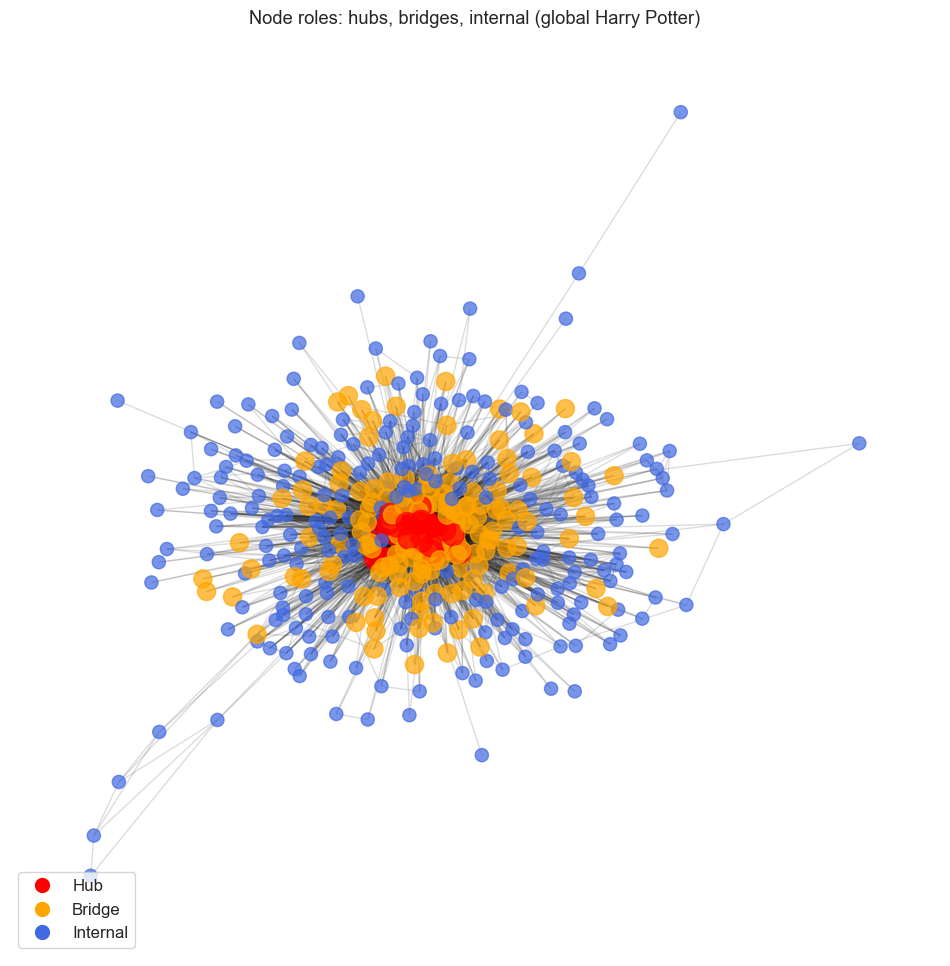

,node,community_id,degree,k_internal,k_external,num_communities_touched,role
3,Harry,0,408,117,291,8,hub
51,Ron,4,301,55,246,7,hub
63,Hermione,1,275,89,186,7,hub
8,Dumbledore,1,240,98,142,7,hub
5,Voldemort,1,195,96,99,6,hub
12,Hagrid,1,175,68,107,7,hub
52,Neville,2,165,32,133,6,hub
48,Ginny,4,164,34,130,7,hub
50,George,4,157,48,109,6,hub
92,Snape,1,157,58,99,6,hub


In [172]:
# Reuse Louvain partition and pos from before
roles_df = node_roles(G, louvain_part, hub_quantile=0.9)
draw_roles(G, roles_df, title="Node roles: hubs, bridges, internal (global Harry Potter)", pos=pos)

# See top hubs:
roles_df[roles_df["role"] == "hub"].head(10)


In [173]:
def community_role_summary(roles_df):
    """
    Aggregate roles per community.
    Returns: DataFrame with counts and fractions of hubs/bridges/internal per community.
    """
    group = roles_df.groupby(["community_id", "role"]).size().unstack(fill_value=0)
    # ensure all columns exist
    for col in ["hub", "bridge", "internal"]:
        if col not in group.columns:
            group[col] = 0
    group["size"] = group["hub"] + group["bridge"] + group["internal"]
    for col in ["hub", "bridge", "internal"]:
        group[f"frac_{col}"] = group[col] / group["size"].replace(0, np.nan)
    return group.reset_index().sort_values(by="size", ascending=False)


In [174]:
role_summary_df = community_role_summary(roles_df)
role_summary_df.head()
print(role_summary_df.to_latex(index=False, float_format="%.3f"))


\begin{tabular}{rrrrrrrr}
\toprule
community_id & bridge & hub & internal & size & frac_hub & frac_bridge & frac_internal \\
\midrule
1 & 17 & 13 & 95 & 125 & 0.104 & 0.136 & 0.760 \\
0 & 43 & 7 & 72 & 122 & 0.057 & 0.352 & 0.590 \\
4 & 23 & 11 & 33 & 67 & 0.164 & 0.343 & 0.493 \\
2 & 35 & 6 & 9 & 50 & 0.120 & 0.700 & 0.180 \\
6 & 18 & 6 & 21 & 45 & 0.133 & 0.400 & 0.467 \\
5 & 15 & 3 & 1 & 19 & 0.158 & 0.789 & 0.053 \\
3 & 1 & 0 & 5 & 6 & 0.000 & 0.167 & 0.833 \\
7 & 1 & 0 & 5 & 6 & 0.000 & 0.167 & 0.833 \\
\bottomrule
\end{tabular}



Estimated gamma (k_min=3): 1.586


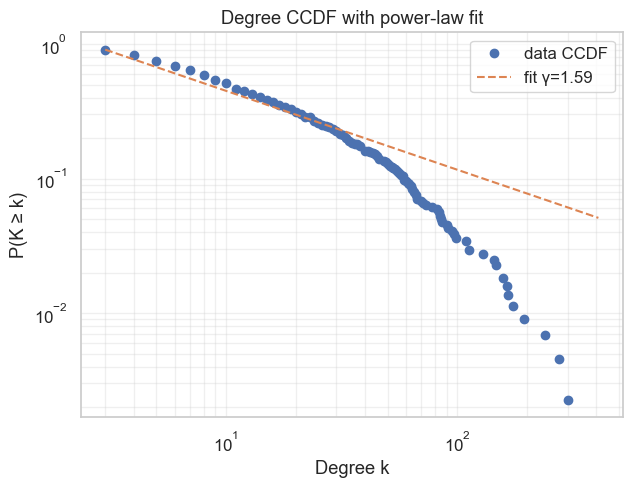

In [175]:
plot_degree_distribution_with_fit(G, k_min=3)


In [176]:
# lets try for more overlapping communities
def cpm_sweep(G, k_values=(3, 4, 5)):
    results = []
    for k in k_values:
        comms, cliques = cpm_overlapping_communities(G, k=k)
        sizes = sorted([len(c) for c in comms], reverse=True)
        results.append((k, len(comms), sizes[:10]))
        print(f"\n=== CPM with k={k} ===")
        print(f"Number of communities: {len(comms)}")
        print(f"Top 10 community sizes: {sizes[:10]}")
    return results

cpm_sweep(G, k_values=(3, 4, 5, 6))




=== CPM with k=3 ===
Number of communities: 1
Top 10 community sizes: [433]

=== CPM with k=4 ===
Number of communities: 3
Top 10 community sizes: [414, 4, 4]

=== CPM with k=5 ===
Number of communities: 5
Top 10 community sizes: [381, 8, 5, 5, 5]

=== CPM with k=6 ===
Number of communities: 5
Top 10 community sizes: [344, 8, 7, 6, 6]


[(3, 1, [433]),
 (4, 3, [414, 4, 4]),
 (5, 5, [381, 8, 5, 5, 5]),
 (6, 5, [344, 8, 7, 6, 6])]


=== CPM k=5 (global HP) (overlapping) ===
Number of communities: 5
Community sizes (top 10): [381, 8, 5, 5, 5]


/var/folders/7b/gg3rf9zj28bfyjwgyw4z4xhw0000gq/T/ipykernel_9920/3774216441.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20")


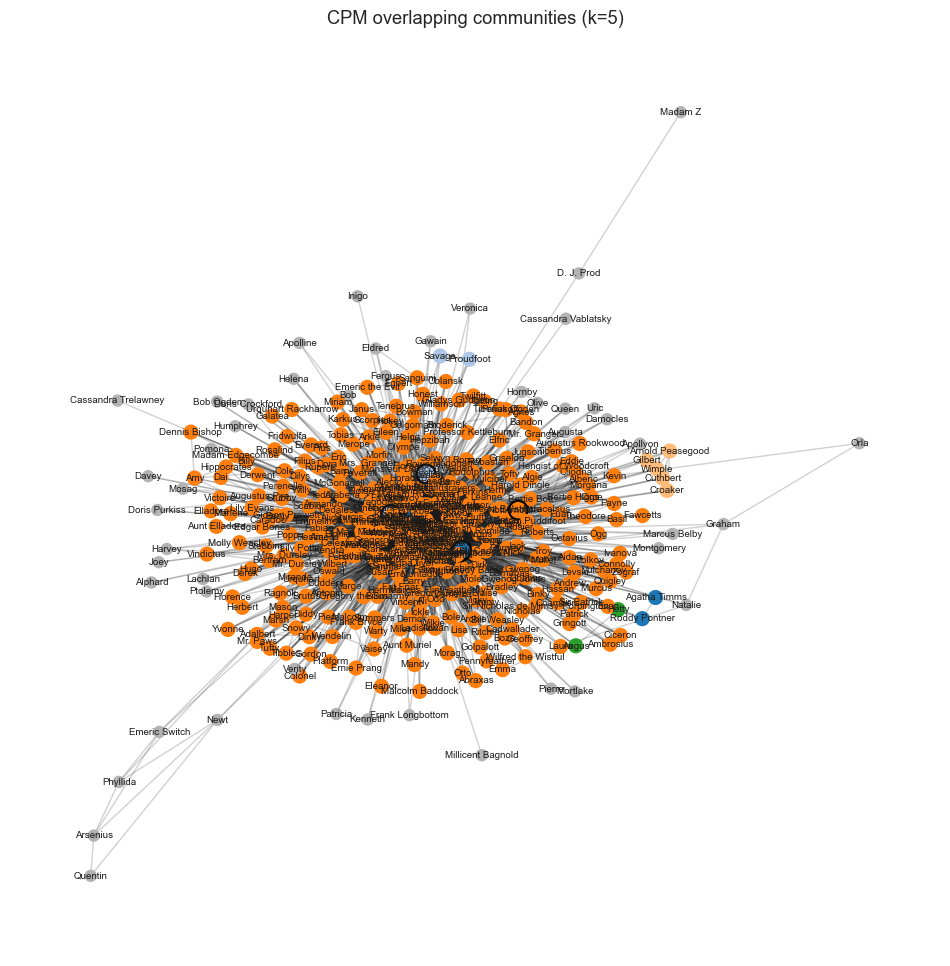

In [177]:
k_best = 5  # or whatever looked good
cpm_comms_kbest, _ = cpm_overlapping_communities(G, k=k_best)
describe_overlapping_communities(cpm_comms_kbest, name=f"CPM k={k_best} (global HP)")
draw_overlapping_communities(G, cpm_comms_kbest, title=f"CPM overlapping communities (k={k_best})", pos=pos)


In [178]:
def filter_by_weight(G, w_min):
    """
    Return subgraph with only edges of weight >= w_min.
    """
    H = nx.Graph()
    for u, v, data in G.edges(data=True):
        w = data.get("weight", 1)
        if w >= w_min:
            H.add_edge(u, v, **data)
    # Keep only nodes that actually appear
    return H

# Example: keep only edges where weight >= 5
G_strong = filter_by_weight(G, w_min=5)
print(G_strong.number_of_nodes(), G_strong.number_of_edges())


147 885



=== CPM with k=3 ===
Number of communities: 3
Top 10 community sizes: [126, 3, 3]

=== CPM with k=4 ===
Number of communities: 1
Top 10 community sizes: [114]

=== CPM with k=5 ===
Number of communities: 1
Top 10 community sizes: [98]

=== CPM strong ties (k=3) (overlapping) ===
Number of communities: 3
Community sizes (top 10): [126, 3, 3]


/var/folders/7b/gg3rf9zj28bfyjwgyw4z4xhw0000gq/T/ipykernel_9920/3774216441.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20")


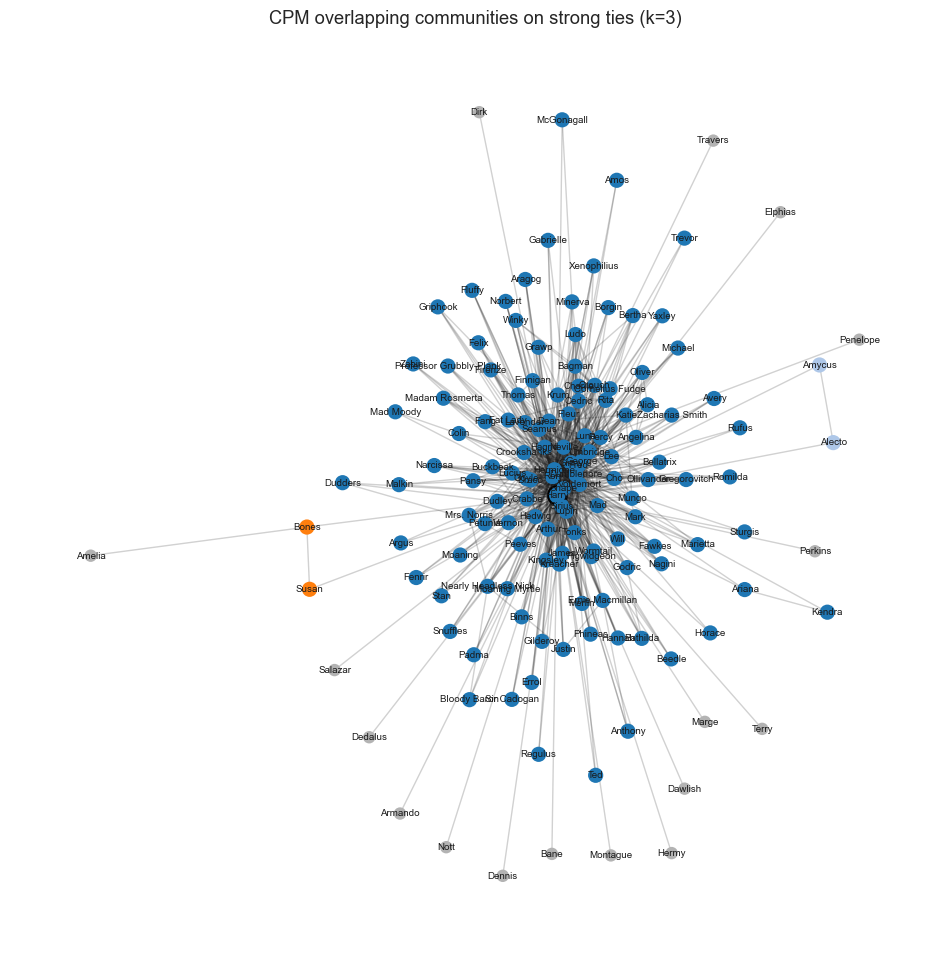

In [179]:
cpm_sweep(G_strong, k_values=(3, 4, 5))

k_best = 3   # for example, lower k now works because the graph is sparser
cpm_comms_strong, _ = cpm_overlapping_communities(G_strong, k=k_best)
describe_overlapping_communities(cpm_comms_strong, name=f"CPM strong ties (k={k_best})")
draw_overlapping_communities(G_strong, cpm_comms_strong,
                             title=f"CPM overlapping communities on strong ties (k={k_best})")


In [180]:
def get_louvain_partition(G):
    partition_dict = community_louvain.best_partition(G, weight="weight")
    return partition_from_dict(partition_dict)


In [181]:
import matplotlib.pyplot as plt

def visualize_communities_book_by_book(graph_gen, method="louvain", seed=42, figsize=(10,10)):
    """
    Visualize communities for each book (1–7) using a given method.
    """
    for book_id in range(1, 8):
        print(f"\n===== Book {book_id} =====")
        G_book = graph_gen.get_graph(book_id)

        # Layout for this book
        pos = nx.spring_layout(G_book, seed=seed)

        # Community detection
        if method == "louvain":
            partition = get_louvain_partition(G_book)
        elif method == "greedy":
            partition = greedy_communities(G_book)
        else:
            raise ValueError("Unknown method")

        # Print stats
        describe_partition(G_book, partition, name=f"Book {book_id} ({method})")

        # Draw
        draw_partition(
            G_book,
            partition,
            title=f"Communities in Book {book_id} ({method})",
            pos=pos,
            figsize=figsize
        )



===== Book 1 =====

=== Book 1 (louvain) ===
Number of communities: 7
Community sizes (top 10): [33, 25, 25, 16, 8, 8, 1]
Modularity: 0.2520


/var/folders/7b/gg3rf9zj28bfyjwgyw4z4xhw0000gq/T/ipykernel_9920/4088690958.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20")


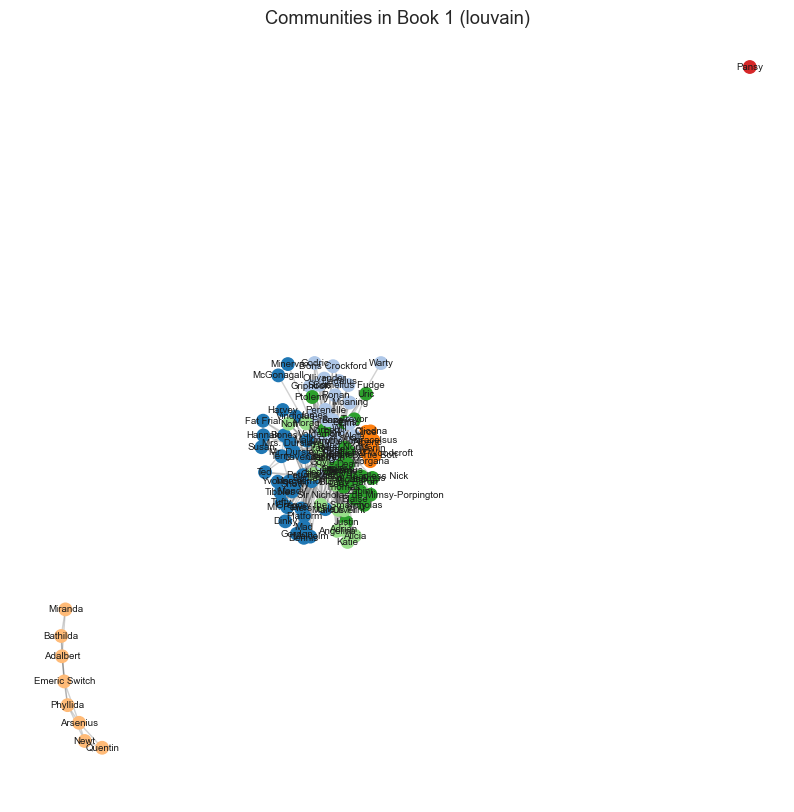


===== Book 2 =====

=== Book 2 (louvain) ===
Number of communities: 8
Community sizes (top 10): [43, 35, 28, 16, 15, 8, 8, 1]
Modularity: 0.1786


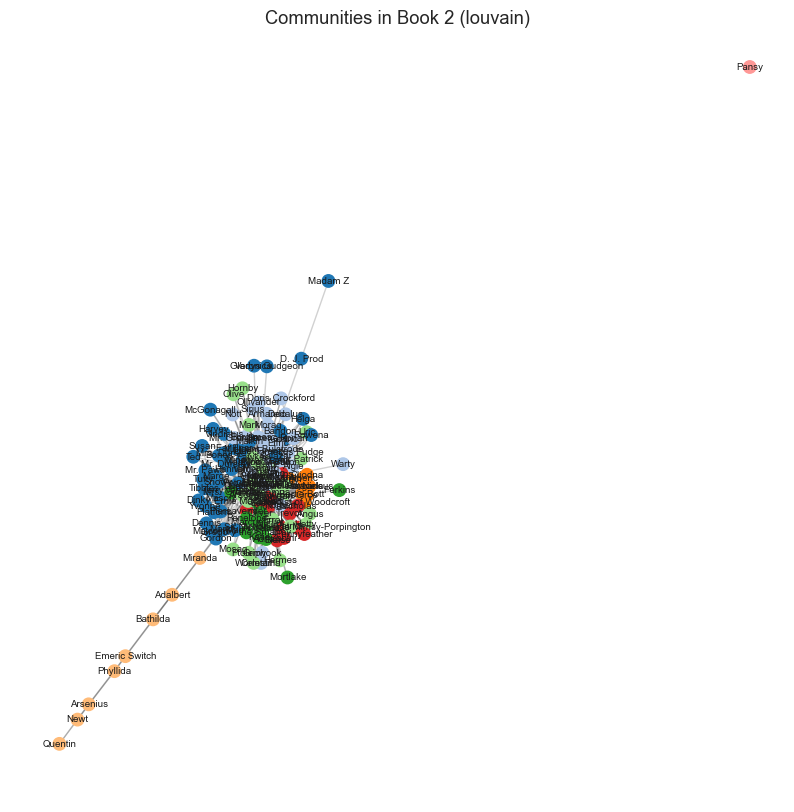


===== Book 3 =====

=== Book 3 (louvain) ===
Number of communities: 8
Community sizes (top 10): [70, 36, 27, 14, 13, 9, 8, 5]
Modularity: 0.1610


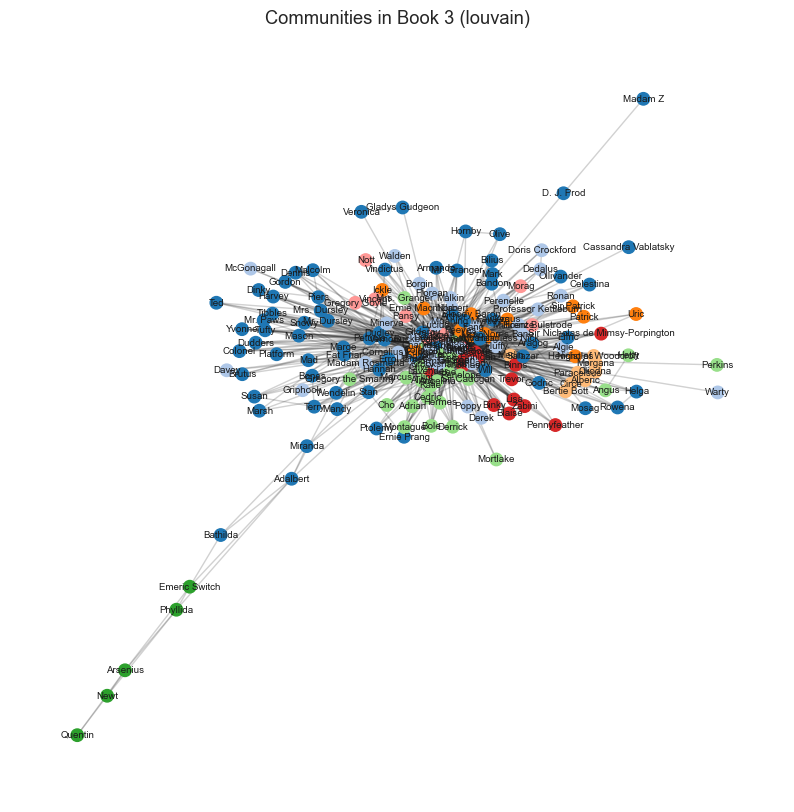


===== Book 4 =====

=== Book 4 (louvain) ===
Number of communities: 8
Community sizes (top 10): [76, 55, 47, 41, 27, 9, 8, 6]
Modularity: 0.1566


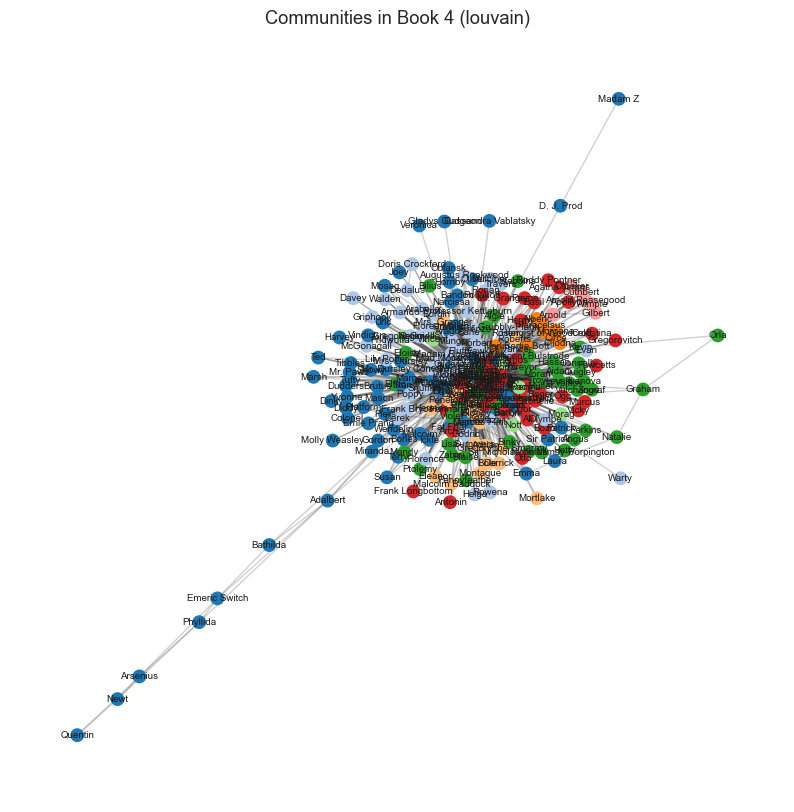


===== Book 5 =====

=== Book 5 (louvain) ===
Number of communities: 8
Community sizes (top 10): [109, 94, 74, 40, 14, 11, 7, 6]
Modularity: 0.1445


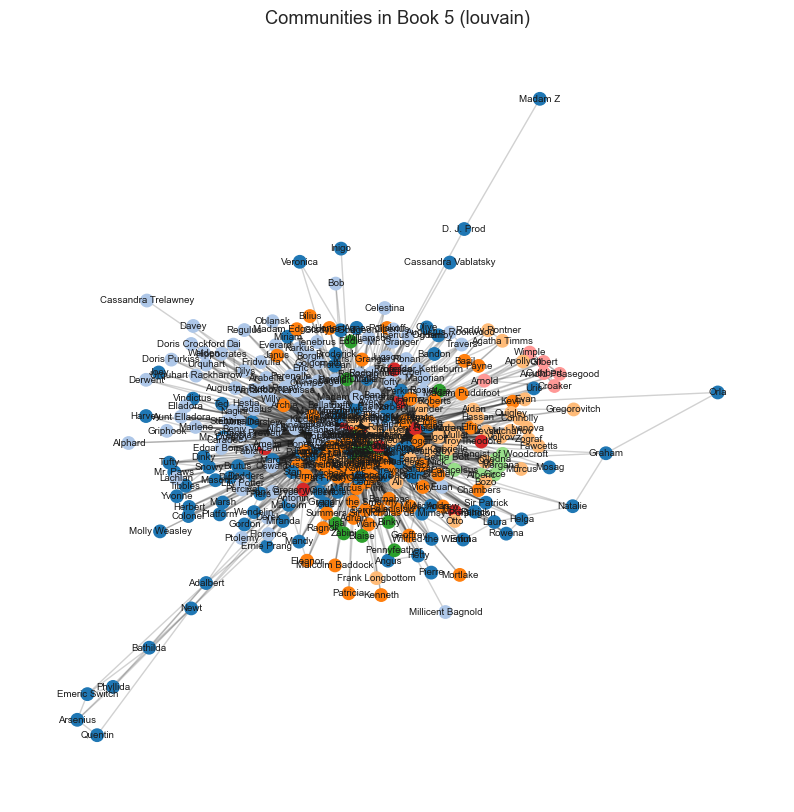


===== Book 6 =====

=== Book 6 (louvain) ===
Number of communities: 7
Community sizes (top 10): [128, 110, 108, 41, 19, 7, 5]
Modularity: 0.1379


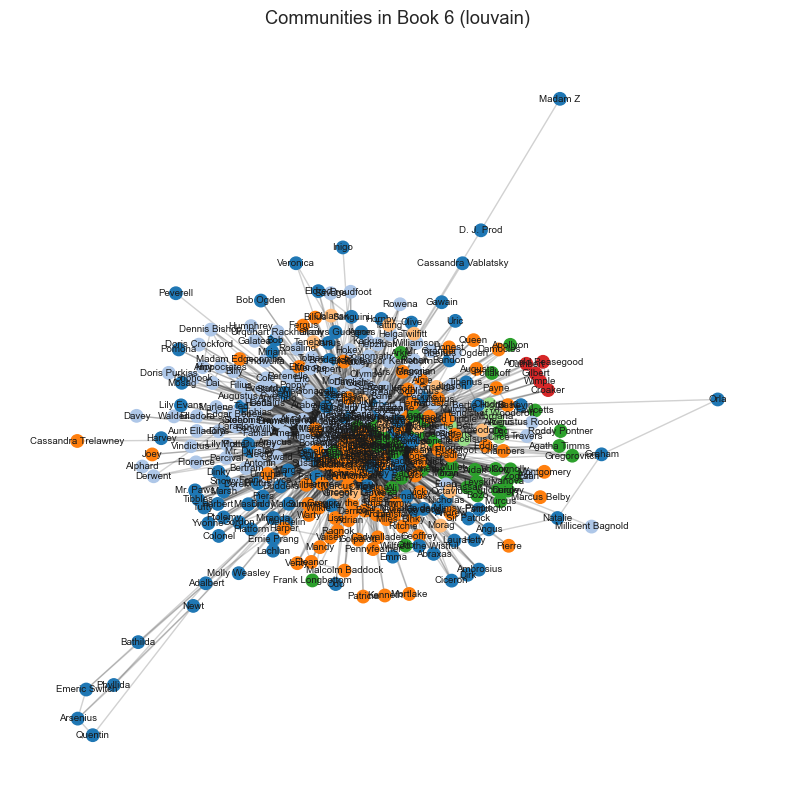


===== Book 7 =====

=== Book 7 (louvain) ===
Number of communities: 9
Community sizes (top 10): [175, 85, 62, 38, 35, 31, 7, 5, 2]
Modularity: 0.1284


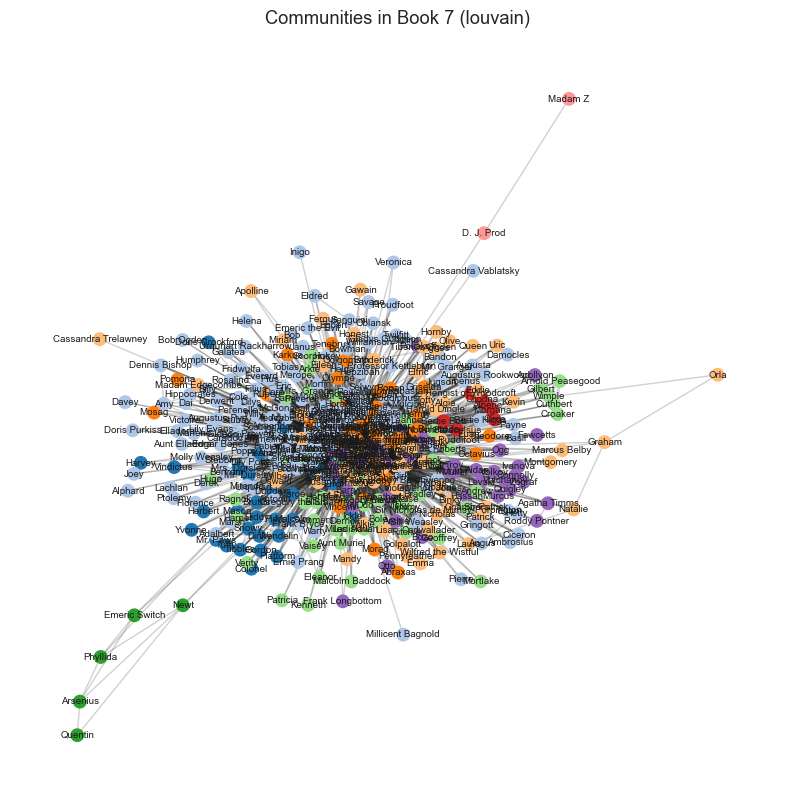

In [182]:
visualize_communities_book_by_book(graph_gen, method="louvain")


In [183]:
# build a global layout based on all nodes in the saga
G_global = graph_gen.get_global_graph()
pos_global = nx.spring_layout(G_global, seed=42)

def visualize_with_global_layout(graph_gen, pos_global, method="louvain"):
    for book_id in range(1, 8):
        print(f"\n===== Book {book_id} =====")
        G_book = graph_gen.get_graph(book_id)

        # subset position only for nodes in this book
        pos_sub = {n: pos_global[n] for n in G_book.nodes()}

        if method == "louvain":
            partition = get_louvain_partition(G_book)
        elif method == "greedy":
            partition = greedy_communities(G_book)
        else:
            raise ValueError("Unknown method")

        describe_partition(G_book, partition, name=f"Book {book_id} ({method})")

        draw_partition(
            G_book,
            partition,
            title=f"Communities in Book {book_id} (global layout)",
            pos=pos_sub,
            figsize=(10,10)
        )



===== Book 1 =====

=== Book 1 (louvain) ===
Number of communities: 7
Community sizes (top 10): [32, 28, 28, 11, 8, 8, 1]
Modularity: 0.2484


/var/folders/7b/gg3rf9zj28bfyjwgyw4z4xhw0000gq/T/ipykernel_9920/4088690958.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20")


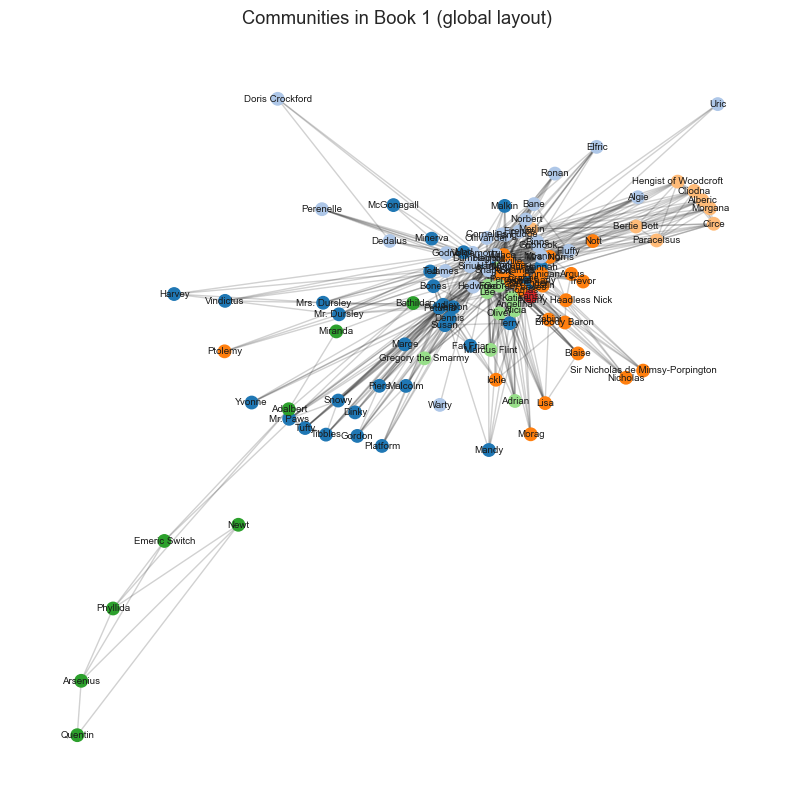


===== Book 2 =====

=== Book 2 (louvain) ===
Number of communities: 8
Community sizes (top 10): [46, 43, 19, 19, 10, 8, 8, 1]
Modularity: 0.1802


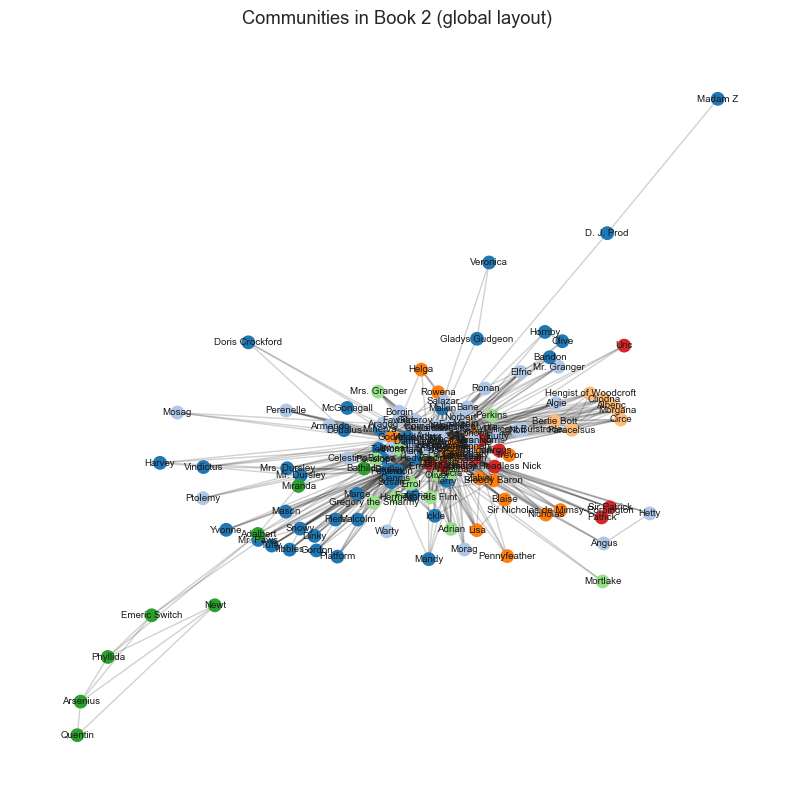


===== Book 3 =====

=== Book 3 (louvain) ===
Number of communities: 8
Community sizes (top 10): [49, 40, 38, 22, 12, 8, 8, 5]
Modularity: 0.1647


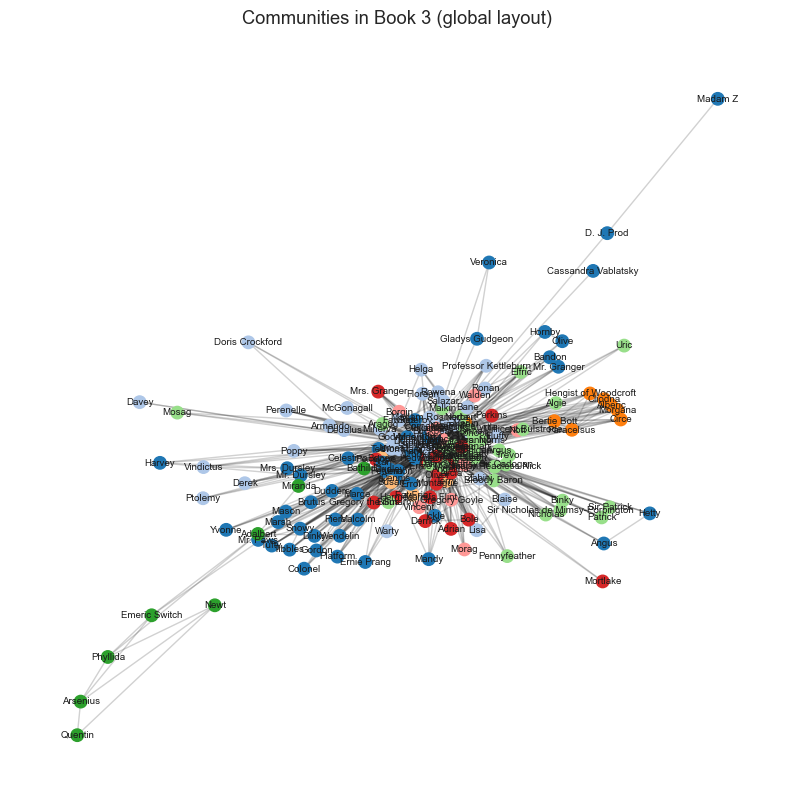


===== Book 4 =====

=== Book 4 (louvain) ===
Number of communities: 11
Community sizes (top 10): [70, 58, 46, 29, 28, 10, 8, 8, 6, 4]
Modularity: 0.1621


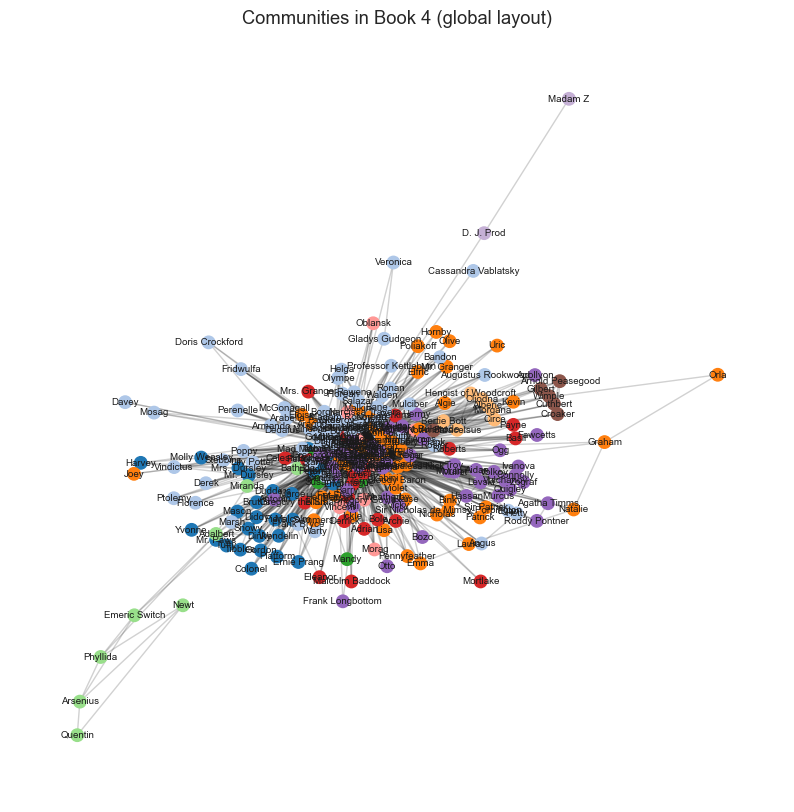


===== Book 5 =====

=== Book 5 (louvain) ===
Number of communities: 9
Community sizes (top 10): [90, 78, 44, 40, 39, 36, 15, 7, 6]
Modularity: 0.1477


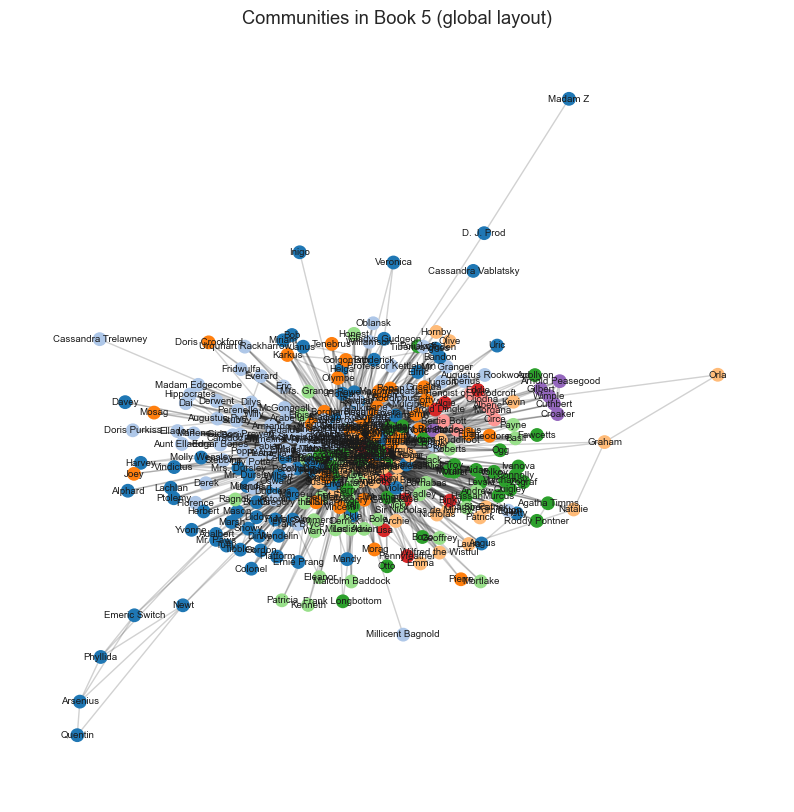


===== Book 6 =====

=== Book 6 (louvain) ===
Number of communities: 7
Community sizes (top 10): [114, 113, 67, 65, 46, 7, 6]
Modularity: 0.1392


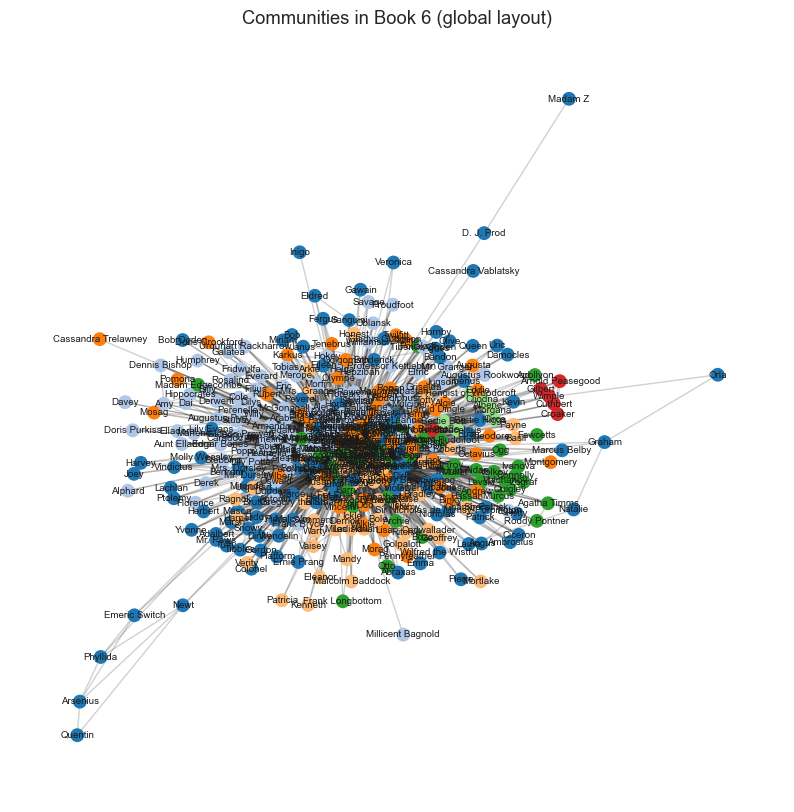


===== Book 7 =====

=== Book 7 (louvain) ===
Number of communities: 10
Community sizes (top 10): [152, 96, 65, 39, 35, 33, 7, 6, 5, 2]
Modularity: 0.1297


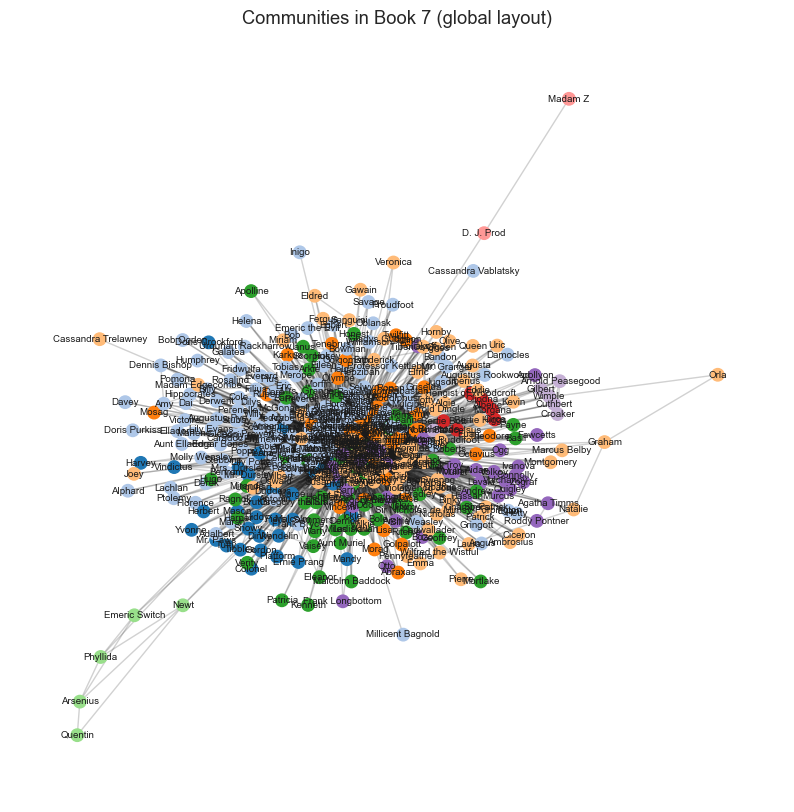

In [184]:
visualize_with_global_layout(graph_gen, pos_global, method="louvain")


In [185]:
def visualize_cpm_book_by_book(graph_gen, k=4, w_min=5):
    for book_id in range(1, 8):
        print(f"\n===== Book {book_id} (CPM k={k}, w_min={w_min}) =====")
        G_book = graph_gen.get_graph(book_id)

        # Strong ties only
        G_strong = filter_by_weight(G_book, w_min=w_min)

        # CPM overlapping
        comms, _ = cpm_overlapping_communities(G_strong, k=k)

        describe_overlapping_communities(comms, name=f"Book {book_id}")

        # Layout
        pos = nx.spring_layout(G_book, seed=42)

        draw_overlapping_communities(
            G_strong,
            comms,
            title=f"CPM Communities (Book {book_id}, k={k}, w_min={w_min})",
            pos={n: pos[n] for n in G_strong.nodes()}
        )



===== Book 1 (CPM k=4, w_min=5) =====

=== Book 1 (overlapping) ===
Number of communities: 4
Community sizes (top 10): [10, 4, 4, 4]


/var/folders/7b/gg3rf9zj28bfyjwgyw4z4xhw0000gq/T/ipykernel_9920/3774216441.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20")


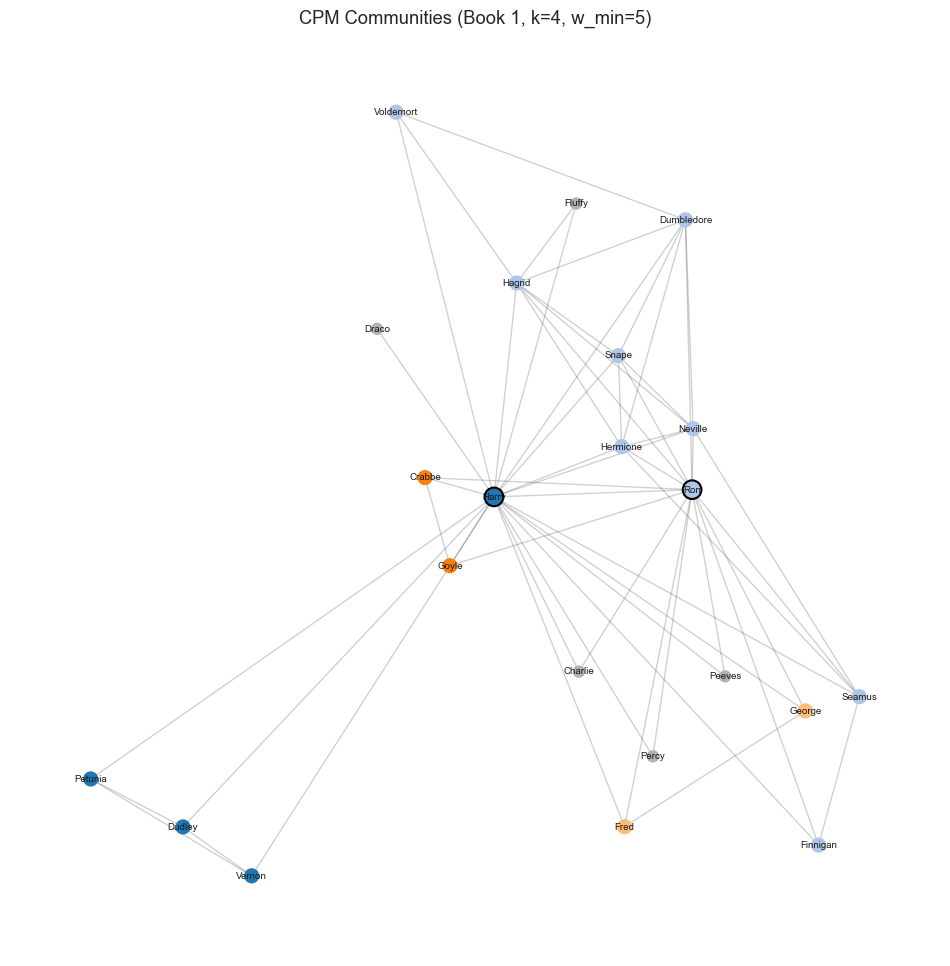


===== Book 2 (CPM k=4, w_min=5) =====

=== Book 2 (overlapping) ===
Number of communities: 2
Community sizes (top 10): [32, 4]


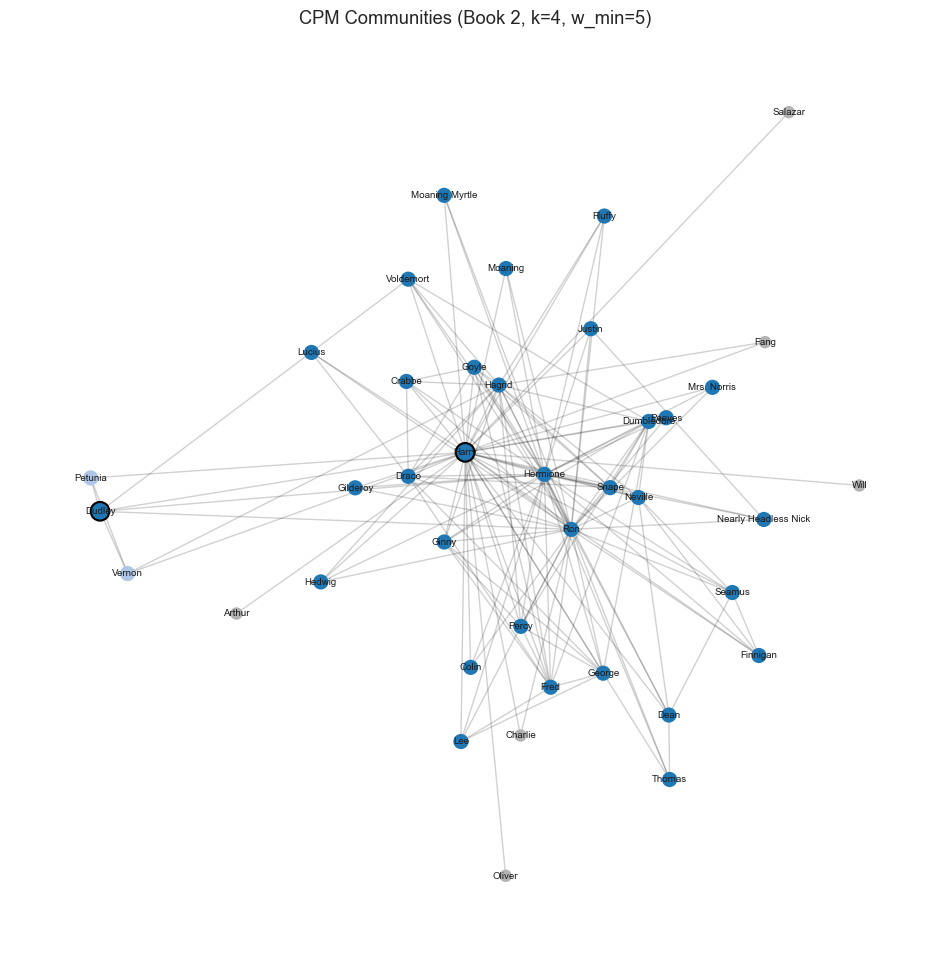


===== Book 3 (CPM k=4, w_min=5) =====

=== Book 3 (overlapping) ===
Number of communities: 1
Community sizes (top 10): [49]


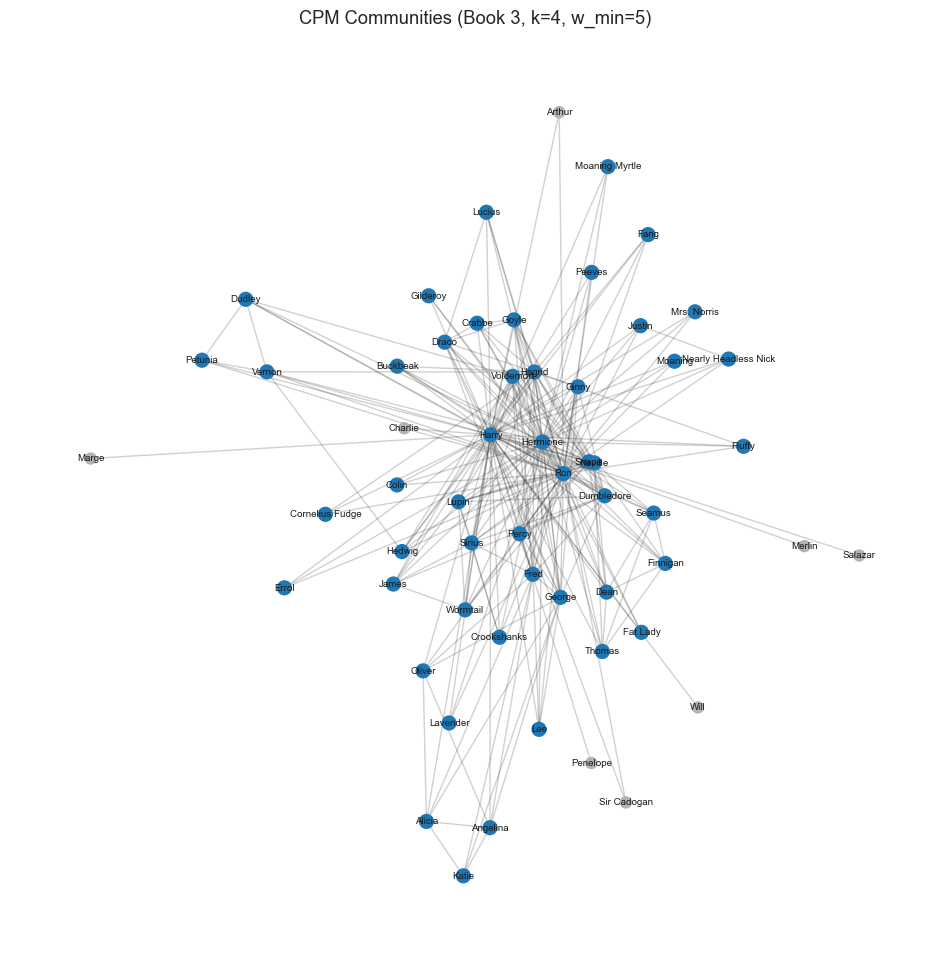


===== Book 4 (CPM k=4, w_min=5) =====

=== Book 4 (overlapping) ===
Number of communities: 1
Community sizes (top 10): [68]


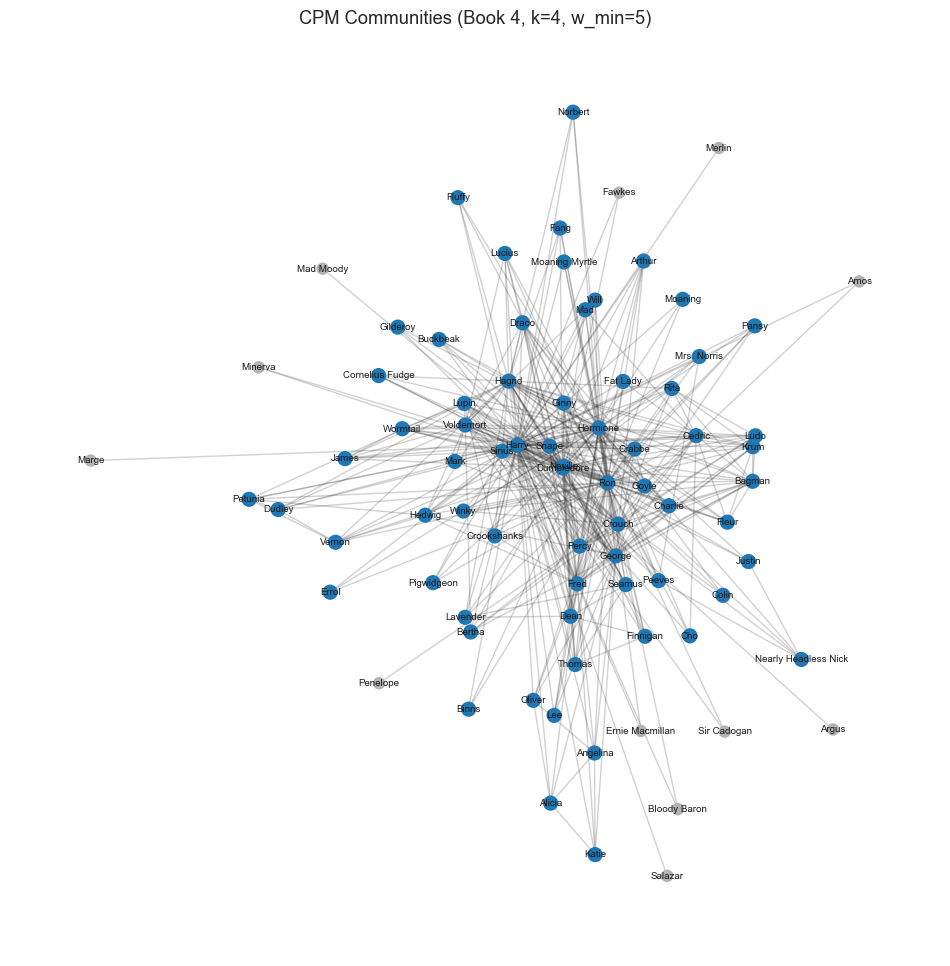


===== Book 5 (CPM k=4, w_min=5) =====

=== Book 5 (overlapping) ===
Number of communities: 1
Community sizes (top 10): [86]


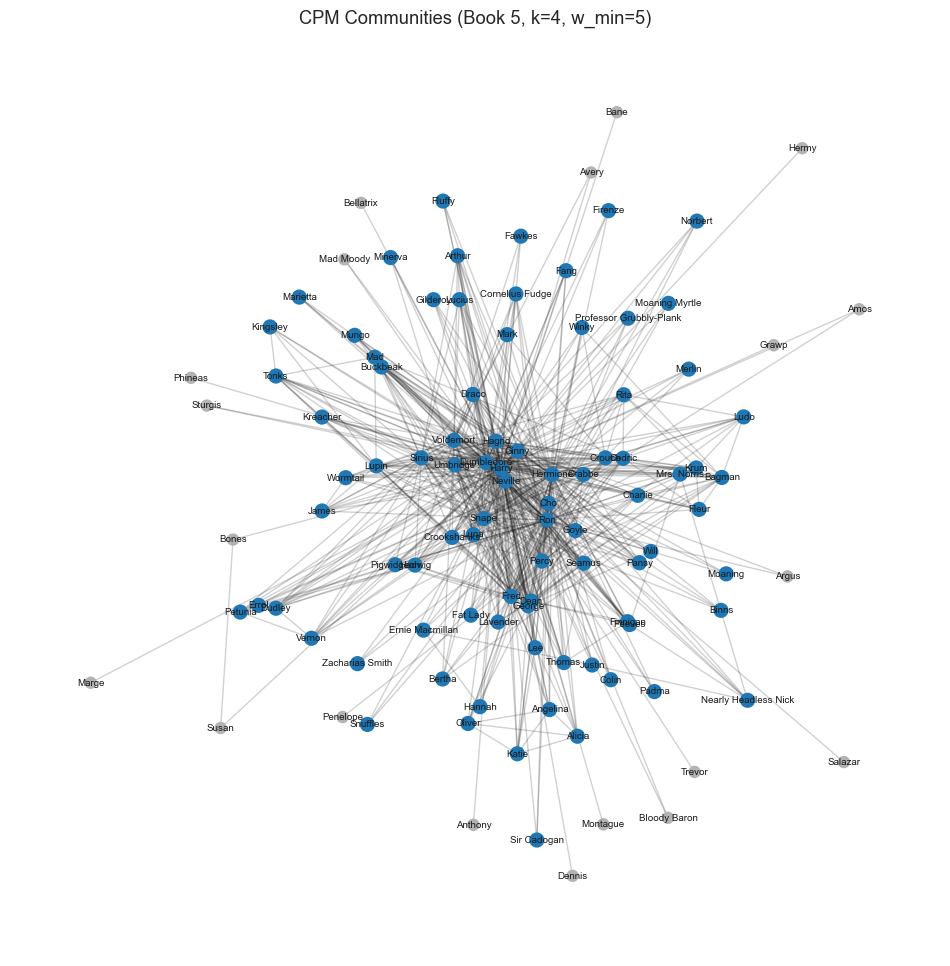


===== Book 6 (CPM k=4, w_min=5) =====

=== Book 6 (overlapping) ===
Number of communities: 1
Community sizes (top 10): [98]


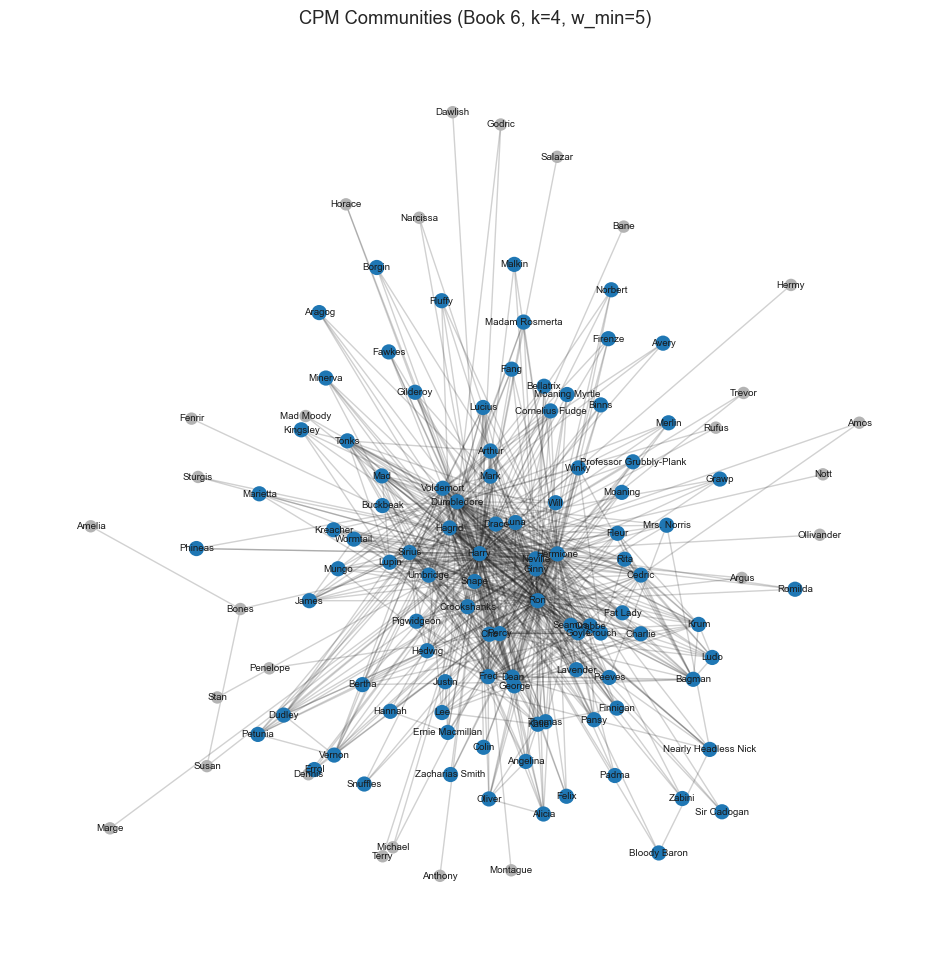


===== Book 7 (CPM k=4, w_min=5) =====

=== Book 7 (overlapping) ===
Number of communities: 1
Community sizes (top 10): [114]


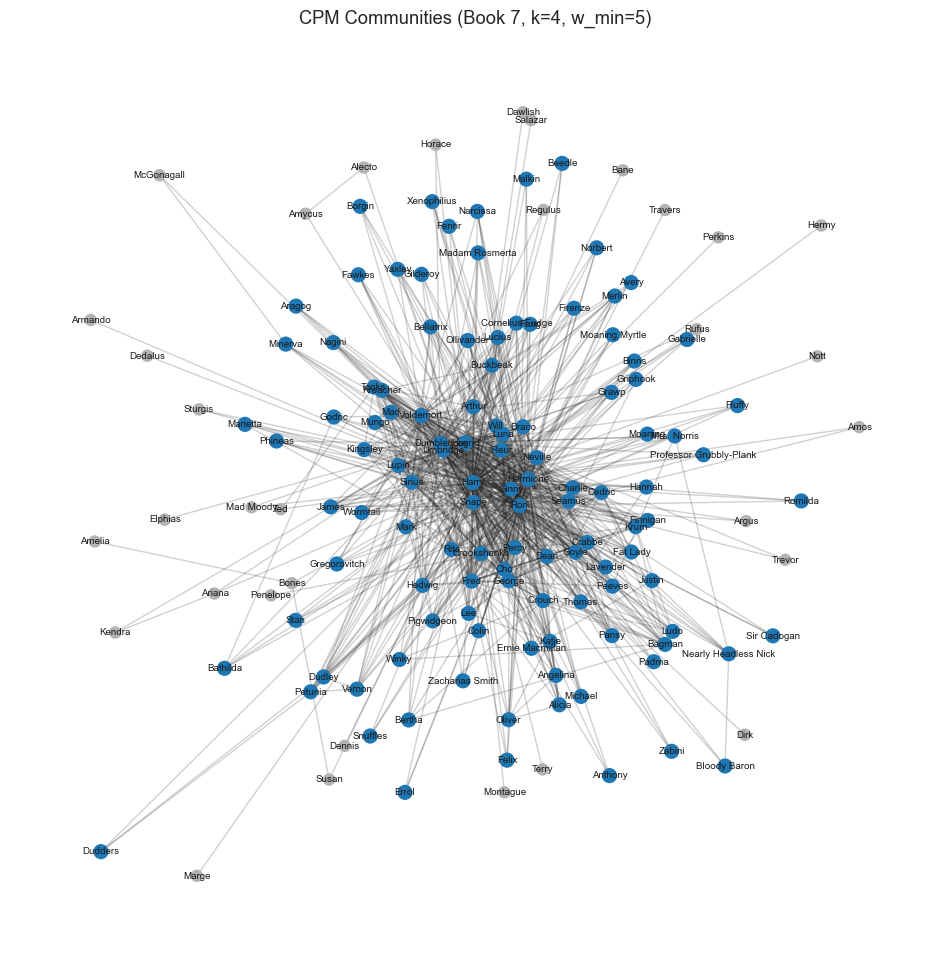

In [186]:
visualize_cpm_book_by_book(graph_gen, k=4, w_min=5)


In [187]:
import matplotlib.pyplot as plt

def community_timeline_plot(graph_gen, method="louvain"):
    community_counts = []

    for book_id in range(1, 8):
        G_book = graph_gen.get_graph(book_id)

        # Detect communities
        if method == "louvain":
            partition = get_louvain_partition(G_book)
        elif method == "greedy":
            partition = greedy_communities(G_book)
        else:
            raise ValueError("Unknown method")

        community_counts.append(len(partition))

    # Plot timeline
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, 8), community_counts, '-o', linewidth=2, markersize=8)
    plt.xticks(range(1, 8))
    plt.xlabel("Book")
    plt.ylabel("Number of Communities")
    plt.title(f"Community Count Timeline ({method} method)")
    plt.grid(True, alpha=0.3)
    plt.show()

    return community_counts


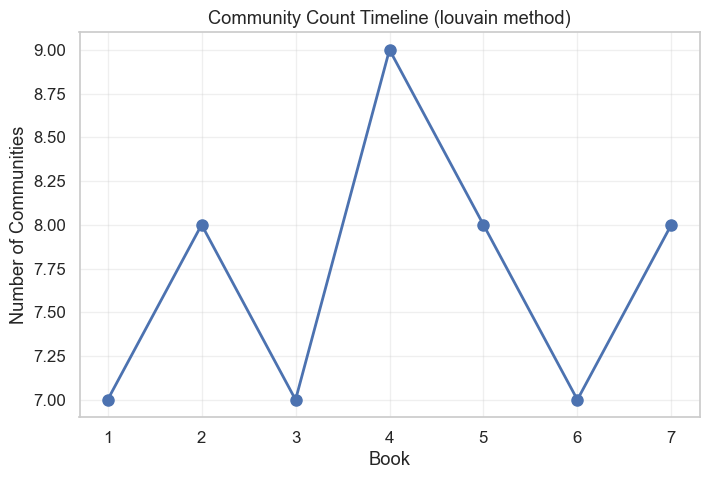

[7, 8, 7, 9, 8, 7, 8]

In [188]:
community_timeline_plot(graph_gen, method="louvain")


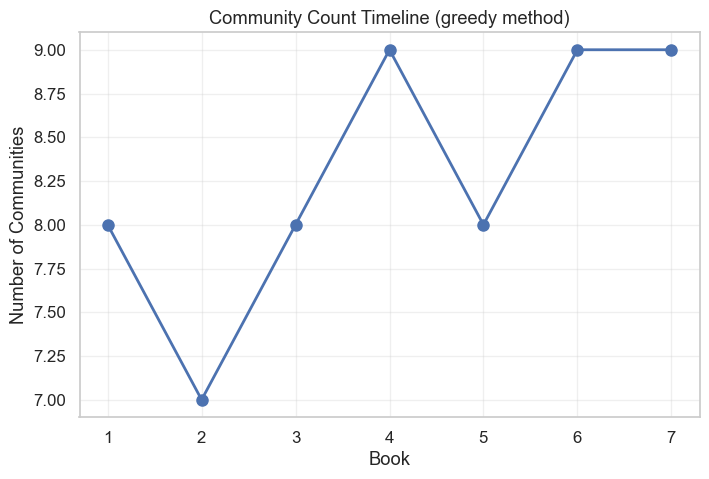

[8, 7, 8, 9, 8, 9, 9]

In [189]:
community_timeline_plot(graph_gen, method="greedy")


In [190]:
def community_overlap_matrix(part_i, part_j):
    """
    Compute overlap matrix between partitions:
    - part_i: communities of book i (list of sets)
    - part_j: communities of book j (list of sets)

    Returns:
        overlap[i][j] = size of intersection between community i and j
    """
    overlap = np.zeros((len(part_i), len(part_j)), dtype=int)
    
    for i, comm_i in enumerate(part_i):
        for j, comm_j in enumerate(part_j):
            overlap[i, j] = len(comm_i & comm_j)

    return overlap


In [191]:
def plot_community_evolution(part_i, part_j, book_i, book_j):
    overlap = community_overlap_matrix(part_i, part_j)
    
    # Normalize for line thickness
    max_overlap = overlap.max() if overlap.max() > 0 else 1

    fig, ax = plt.subplots(figsize=(10, 5))
    
    # positions on left and right
    left_y = np.linspace(0, 1, len(part_i))
    right_y = np.linspace(0, 1, len(part_j))
    
    # plot left nodes
    for idx, y in enumerate(left_y):
        ax.text(0.05, y, f"C{idx} ({len(part_i[idx])})", va='center', ha='left')
    
    # plot right nodes
    for idx, y in enumerate(right_y):
        ax.text(0.95, y, f"C{idx} ({len(part_j[idx])})", va='center', ha='right')
    
    # draw flows
    for i in range(len(part_i)):
        for j in range(len(part_j)):
            if overlap[i, j] > 0:
                ax.plot(
                    [0.15, 0.85],
                    [left_y[i], right_y[j]],
                    linewidth=3 * (overlap[i, j] / max_overlap),
                    alpha=0.6,
                    color="royalblue"
                )
    
    ax.set_title(f"Community Evolution: Book {book_i} → Book {book_j}")
    ax.axis('off')
    plt.show()


In [192]:
def plot_all_evolutions(graph_gen, method="louvain"):
    for book in range(1, 7):
        G_i = graph_gen.get_graph(book)
        G_j = graph_gen.get_graph(book+1)

        if method == "louvain":
            part_i = get_louvain_partition(G_i)
            part_j = get_louvain_partition(G_j)
        elif method == "greedy":
            part_i = greedy_communities(G_i)
            part_j = greedy_communities(G_j)
        else:
            raise ValueError("Unknown method")

        plot_community_evolution(part_i, part_j, book, book+1)


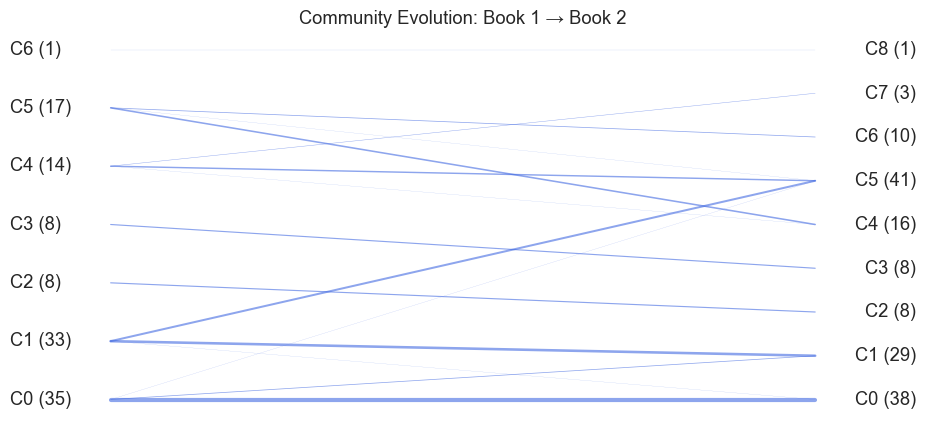

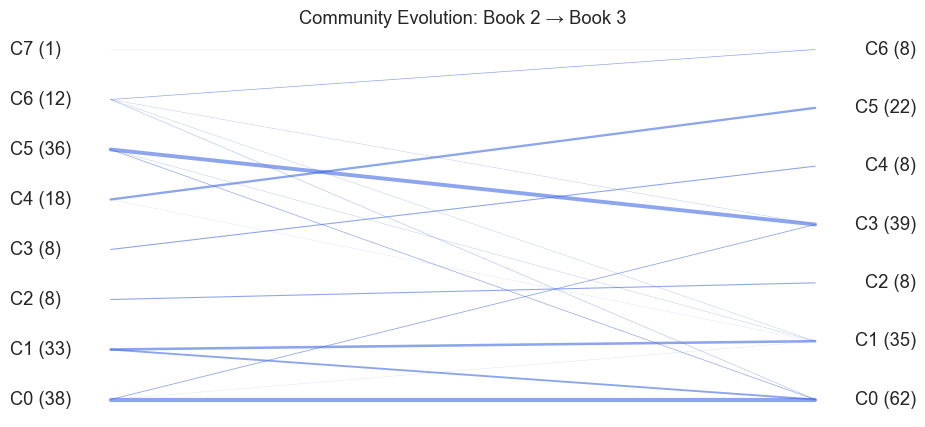

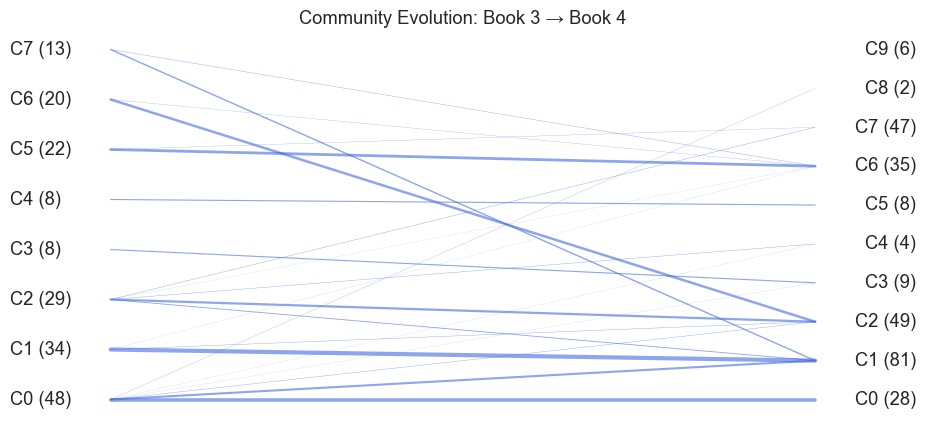

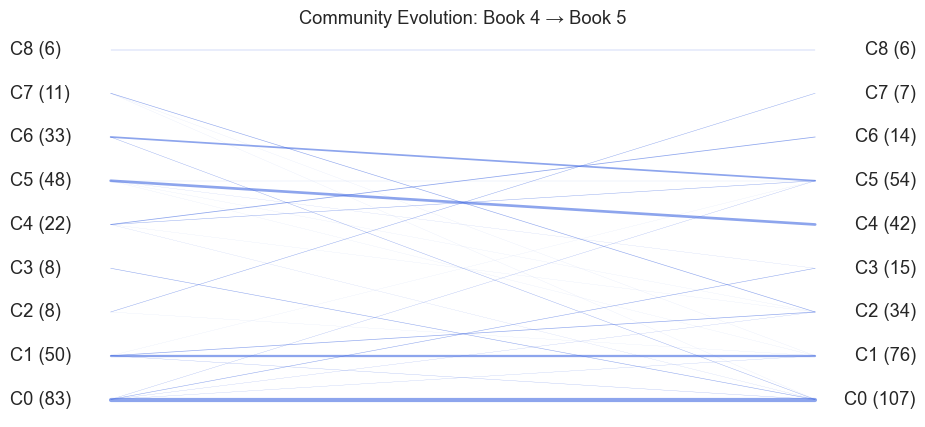

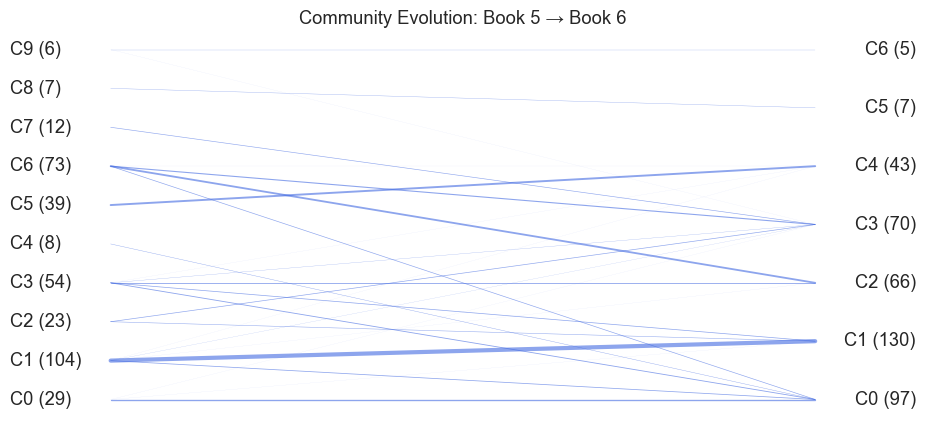

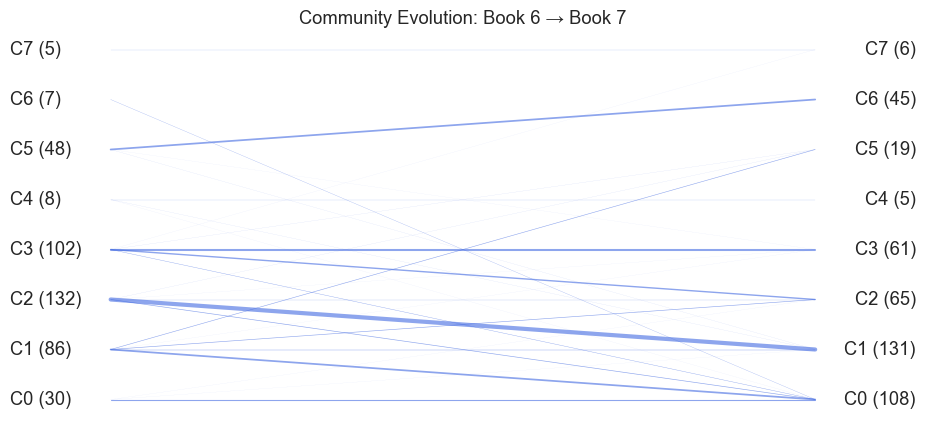

In [193]:
plot_all_evolutions(graph_gen, method="louvain")


In [194]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import math
import seaborn as sns

class NetworkAnalysis:

    # ------------------------------------------------------------------
    # BASIC INFO
    # ------------------------------------------------------------------
    @staticmethod
    def basic_info(G):
        return {
            "num_nodes": G.number_of_nodes(),
            "num_edges": G.number_of_edges(),
        }

    # ------------------------------------------------------------------
    # DEGREE DISTRIBUTION
    # ------------------------------------------------------------------
    @staticmethod
    def degree_distribution(G):
        degrees = np.array([deg for _, deg in G.degree()])
        unique_deg, counts = np.unique(degrees, return_counts=True)
        pmf = counts / counts.sum()
        sorted_deg = np.sort(degrees)
        ccdf = 1.0 - np.arange(1, len(sorted_deg) + 1) / len(sorted_deg)

        return {
            "degrees": degrees,
            "unique_deg": unique_deg,
            "pmf": pmf,
            "sorted_deg": sorted_deg,
            "ccdf": ccdf,
            "average_degree": degrees.mean(),
            "max_degree": degrees.max(),
            "min_degree": degrees.min(),
        }

    # ------------------------------------------------------------------
    # CLUSTERING
    # ------------------------------------------------------------------
    @staticmethod
    def clustering_metrics(G):
        avg_clust = nx.average_clustering(G)
        local_clust = nx.clustering(G)
        return {
            "average_clustering": avg_clust,
            "local_clustering": local_clust,
        }

    # ------------------------------------------------------------------
    # PATH LENGTH & DIAMETER
    # ------------------------------------------------------------------
    @staticmethod
    def path_metrics(G):
        if nx.is_connected(G):
            avg_path = nx.average_shortest_path_length(G)
            diameter = nx.diameter(G)
        else:
            giant = max(nx.connected_components(G), key=len)
            sg = G.subgraph(giant)
            avg_path = nx.average_shortest_path_length(sg)
            diameter = nx.diameter(sg)

        return {
            "average_path_length": avg_path,
            "diameter": diameter,
        }

    # ------------------------------------------------------------------
    # DENSITY
    # ------------------------------------------------------------------
    @staticmethod
    def density(G):
        return nx.density(G)

    # ------------------------------------------------------------------
    # CENTRALITY
    # ------------------------------------------------------------------
    @staticmethod
    def centralities(G):
        return {
            "degree_centrality": nx.degree_centrality(G),
            "betweenness_centrality": nx.betweenness_centrality(G),
            "closeness_centrality": nx.closeness_centrality(G),
        }

    # ------------------------------------------------------------------
    # SMALL-WORLD PROPERTY
    # ------------------------------------------------------------------
    @staticmethod
    def small_world_property(N, avg_deg, observed_avg_path):
        if avg_deg <= 1:
            return False  # can't take log or too sparse
        expected_d = math.log(N) / math.log(avg_deg)
        rel_error = abs(observed_avg_path - expected_d) / expected_d
        return rel_error < 0.30

    # ------------------------------------------------------------------
    # GLOBAL + PER-NODE METRICS
    # ------------------------------------------------------------------
    @staticmethod
    def compute_all(G):
        basic = NetworkAnalysis.basic_info(G)
        dist = NetworkAnalysis.degree_distribution(G)
        clust = NetworkAnalysis.clustering_metrics(G)
        paths = NetworkAnalysis.path_metrics(G)
        central = NetworkAnalysis.centralities(G)

        is_conn = nx.is_connected(G)
        largest_comp = len(max(nx.connected_components(G), key=len))
        assortativity = nx.degree_assortativity_coefficient(G)

        N = basic["num_nodes"]
        avg_deg = dist["average_degree"]
        avg_path = paths["average_path_length"]

        small_world = NetworkAnalysis.small_world_property(N, avg_deg, avg_path)

        global_metrics = {
            "num_nodes": N,
            "num_edges": basic["num_edges"],
            "average_degree": avg_deg,
            "max_degree": dist["max_degree"],
            "min_degree": dist["min_degree"],
            "average_clustering": clust["average_clustering"],
            "density": NetworkAnalysis.density(G),
            "average_path_length": avg_path,
            "diameter": paths["diameter"],
            "is_connected": is_conn,
            "largest_component_size": largest_comp,
            "degree_assortativity": assortativity,
            "small_world_property": small_world,
        }

        global_df = pd.DataFrame([global_metrics])

        node_list = list(G.nodes())
        per_node_df = pd.DataFrame({
            "node": node_list,
            "degree": [G.degree(n) for n in node_list],
            "local_clustering": [clust["local_clustering"][n] for n in node_list],
            "degree_centrality": [central["degree_centrality"][n] for n in node_list],
            "betweenness_centrality": [central["betweenness_centrality"][n] for n in node_list],
            "closeness_centrality": [central["closeness_centrality"][n] for n in node_list],
        })

        return global_df, per_node_df

    # ------------------------------------------------------------------
    # DEGREE DISTRIBUTION PLOTS
    # ------------------------------------------------------------------
    @staticmethod
    def generate_degree_distribution(G):
        sns.set(style="whitegrid", context="talk", palette="pastel")
    
        dist = NetworkAnalysis.degree_distribution(G)
        degrees = dist["degrees"]
        unique_deg = dist["unique_deg"]
        pmf = dist["pmf"]
        sorted_deg = dist["sorted_deg"]
        ccdf = dist["ccdf"]
    
        fig = plt.figure(figsize=(14, 10))
        bins = np.arange(min(degrees)-0.5, max(degrees)+1.5, 1)

        ax_hist = plt.subplot2grid((2, 2), (0, 0), colspan=2)
        sns.histplot(degrees, bins=bins, kde=False, color="royalblue", alpha=0.8, ax=ax_hist)
        ax_hist.set_xlabel("Degree")
        ax_hist.set_ylabel("Count")
        ax_hist.set_title("Degree Histogram")
        ax_hist.grid(True, ls="--", lw=0.5)

        ax_pmf = plt.subplot2grid((2, 2), (1, 0))
        sns.scatterplot(x=unique_deg, y=pmf, s=50, color="steelblue", alpha=0.8, ax=ax_pmf)
        ax_pmf.set_xscale("log")
        ax_pmf.set_yscale("log")
        ax_pmf.set_xlabel("log (Degree (k))")
        ax_pmf.set_ylabel("log (P(k))")
        ax_pmf.set_title("PMF of Degree Distribution")
        ax_pmf.grid(True, which="both", ls="--", lw=0.5)

        ax_ccdf = plt.subplot2grid((2, 2), (1, 1))
        sns.scatterplot(x=sorted_deg, y=ccdf, s=50, color="tomato", alpha=0.8, ax=ax_ccdf)
        ax_ccdf.set_xscale("log")
        ax_ccdf.set_yscale("log")
        ax_ccdf.set_xlabel("log (Degree (k))")
        ax_ccdf.set_ylabel("log (P(K > k))")
        ax_ccdf.set_title("CCDF of Degree Distribution")
        ax_ccdf.grid(True, which="both", ls="--", lw=0.5)

        plt.suptitle("Degree Distribution of the Network", fontsize=18, weight="bold")
        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

In [195]:
k = 5
cpm_comms_k5, cliques = cpm_overlapping_communities(G_global, k=k)


In [196]:
def cpm_extended_table(G, cpm_comms, cliques):
    rows = []
    
    # map clique -> community id
    clique2community = {}
    for cid, comm in enumerate(cpm_comms):
        for clique in cliques:
            if set(clique).issubset(comm):
                clique2community.setdefault(cid, 0)
                clique2community[cid] += 1
    
    # count node overlaps
    from collections import Counter
    node_counts = Counter(n for comm in cpm_comms for n in comm)
    
    for cid, comm in enumerate(cpm_comms):
        nodes = list(comm)
        subG = G.subgraph(nodes)
        
        rows.append({
            "community_id": cid,
            "size": len(nodes),
            "num_cliques": clique2community.get(cid, 0),
            "density": nx.density(subG),
            "avg_degree": sum(dict(subG.degree()).values()) / len(nodes),
            "num_overlapping_nodes": sum(1 for n in nodes if node_counts[n] > 1)
        })
    
    return pd.DataFrame(rows)

cpm_ext_df = cpm_extended_table(G_global, cpm_comms_k5, cliques)
cpm_ext_df


,community_id,size,num_cliques,density,avg_degree,num_overlapping_nodes
0,0,5,1,1.000000,4.000000,3
1,1,5,1,1.000000,4.000000,3
2,2,381,2800,0.072952,27.721785,11
3,3,8,2,0.964286,6.750000,3
4,4,5,1,1.000000,4.000000,3


In [197]:
import ast
import numpy as np

def fix_categories(x):
    # Convert NaN → empty list
    if isinstance(x, float) and np.isnan(x):
        return []
    # Convert strings like "['A', 'B']" → real lists
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return []
    # Already a list → return as is
    if isinstance(x, list):
        return x
    # Fallback
    return []

df['categories'] = df['categories'].apply(fix_categories)


In [198]:
CATEGORY_MAP = {
    "gryffindor": "Gryffindor",
    "gryff": "Gryffindor",
    "slytherin": "Slytherin",
    "slyth": "Slytherin",
    "ravenclaw": "Ravenclaw",
    "raven": "Ravenclaw",
    "huffle": "Hufflepuff",
    "hufflepuff": "Hufflepuff",
    "staff": "Hogwarts Staff",
    "frog": "Chocolate Frog Card",
    "mom": "Ministry of Magic",
    "da": "Dumbledore’s Army",
    "de": "Death Eater",
    "ootp": "Order of the Phoenix",
    "quidd": "Quidditch Player",
    "quidditch": "Quidditch Player",
    "slug": "Slug Club",
    "slug club": "Slug Club",
    "black": "Related to the Blacks"
}


In [199]:
def normalize_category(cat):
    """
    Renames categories using CATEGORY_MAP.
    If no mapping is found, keep the original category.
    """
    if not isinstance(cat, str):
        return cat

    c = cat.strip().lower()

    # Attempt substring match
    for key, val in CATEGORY_MAP.items():
        if key in c:
            return val

    # If no match → keep original
    return cat


In [200]:
def clean_categories_list(cat_list):
    if not isinstance(cat_list, list):
        return []

    cleaned = []
    for cat in cat_list:
        mapped = normalize_category(cat)
        cleaned.append(mapped)

    return cleaned

df['categories'] = df['categories'].apply(clean_categories_list)


In [201]:
import ast
import numpy as np

def ensure_list(x):
    if isinstance(x, list):
        return x
    if isinstance(x, float) and np.isnan(x):
        return []
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return [x]
    return [x]

df['categories'] = df['categories'].apply(ensure_list)


In [204]:
df["name_clean"] = df["name"].astype(str).str.strip().str.lower()


In [205]:
def make_cpm_partition_dict(cpm_comms):
    """
    Convert CPM overlapping communities into node -> [community_ids] format.
    """
    part = {}
    for cid, comm in enumerate(cpm_comms):
        for n in comm:
            part.setdefault(n, []).append(cid)
    return part

cpm_partition_dict = make_cpm_partition_dict(cpm_comms_k5)


In [206]:
louvain_partition_dict = community_louvain.best_partition(G_global, weight="weight")


In [207]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

def plot_category_vs_communities(G, df, partition_dict, title, overlap=False):
    """
    G: networkx graph
    df: dataframe with 'name' and 'name_clean' and 'categories'
    partition_dict:
        - Louvain: node -> community_id (int)
        - CPM: node -> [community_ids]
    overlap: whether the communities are overlapping (CPM)
    """

    rows = []

    for node in G.nodes():
        node_clean = str(node).strip().lower()

        # skip nodes not in df
        if node_clean not in df['name_clean'].values:
            continue

        # retrieve categories
        categories = df.loc[df['name_clean'] == node_clean, 'categories'].values[0]
        if not isinstance(categories, list):
            continue
        if len(categories) == 0:
            continue

        # get communities for node
        comms = partition_dict.get(node, [])
        if not overlap:  # Louvain: single community
            comms = [comms]

        # record all (category, community) pairs
        for c in categories:
            for comm in comms:
                rows.append({"category": c, "community": comm})

    df_cross = pd.DataFrame(rows)

    if df_cross.empty:
        print("⚠️ ERROR: No matching names — confusion matrix empty!")
        print("Example G nodes:", list(G.nodes())[:10])
        print("Example df names:", df['name'].head(10).tolist())
        return None

    # build confusion matrix
    conf_mat = pd.crosstab(df_cross["category"], df_cross["community"])

    # plot
    plt.figure(figsize=(14, 7))
    sns.set(style="whitegrid", font_scale=1.1)

    sns.heatmap(
        conf_mat,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=0.5,
        linecolor="lightgray"
    )

    plt.title(title, fontsize=14)
    plt.xlabel("Community ID")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()

    return conf_mat


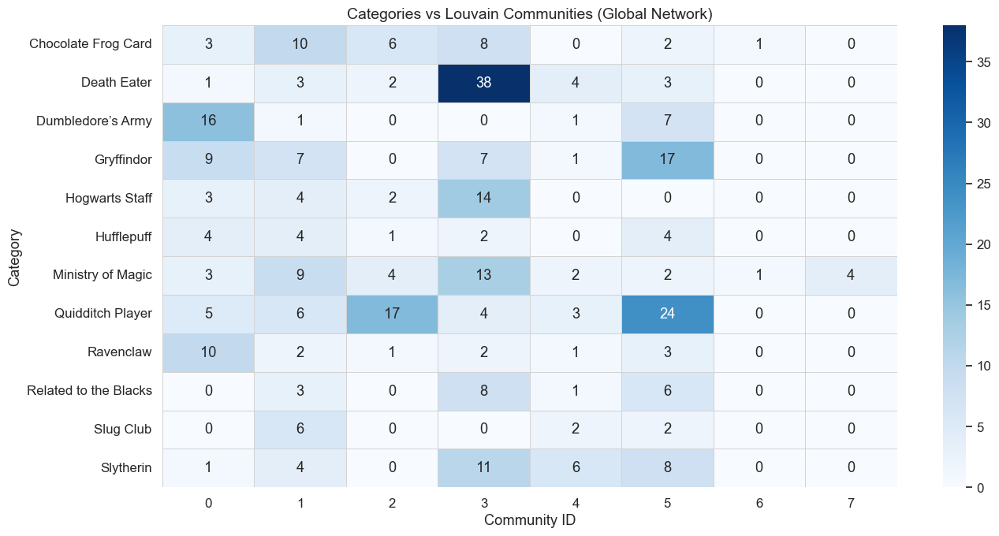

In [208]:
conf_louvain = plot_category_vs_communities(
    G_global,
    df,
    louvain_partition_dict,
    title="Categories vs Louvain Communities (Global Network)",
    overlap=False
)


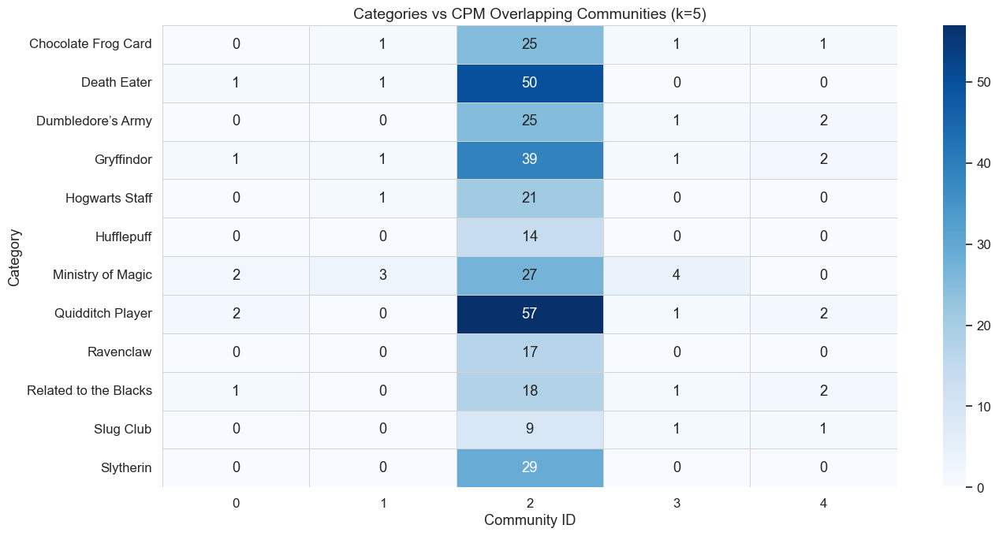

In [209]:
conf_cpm = plot_category_vs_communities(
    G_global,
    df,
    cpm_partition_dict,
    title="Categories vs CPM Overlapping Communities (k=5)",
    overlap=True
)


In [212]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_side_by_side(conf_louvain, conf_cpm, title_louvain="Louvain", title_cpm="CPM (k=5)"):
    # --- Ensure both matrices use the same row order ---
    all_cats = sorted(set(conf_louvain.index) | set(conf_cpm.index))
    
    conf_louvain = conf_louvain.reindex(all_cats).fillna(0).astype(int)
    conf_cpm = conf_cpm.reindex(all_cats).fillna(0).astype(int)

    # --- Shared color scale ---
    vmax = max(conf_louvain.values.max(), conf_cpm.values.max())

    # --- Plot ---
    fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)

    sns.heatmap(
        conf_louvain, 
        annot=True, fmt="d",
        cmap="Blues", vmax=vmax,
        linewidths=0.5, linecolor="lightgray",
        cbar=False, ax=axes[0],
        annot_kws={"size":10, "weight":'bold'}
    )
    axes[0].set_title(title_louvain, fontsize=14)
    axes[0].set_ylabel("Category", fontsize=12)
    axes[0].set_xlabel("Community ID", fontsize=12)
    axes[0].tick_params(rotation=45)

    sns.heatmap(
        conf_cpm, 
        annot=True, fmt="d",
        cmap="Blues", vmax=vmax,
        linewidths=0.5, linecolor="lightgray",
        cbar=True, ax=axes[1],
        annot_kws={"size":10, "weight":'bold'}
    )
    axes[1].set_title(title_cpm, fontsize=14)
    axes[1].set_xlabel("Community ID", fontsize=12)
    axes[1].tick_params(rotation=45)

    plt.suptitle("Category Alignment with Community Structures", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()


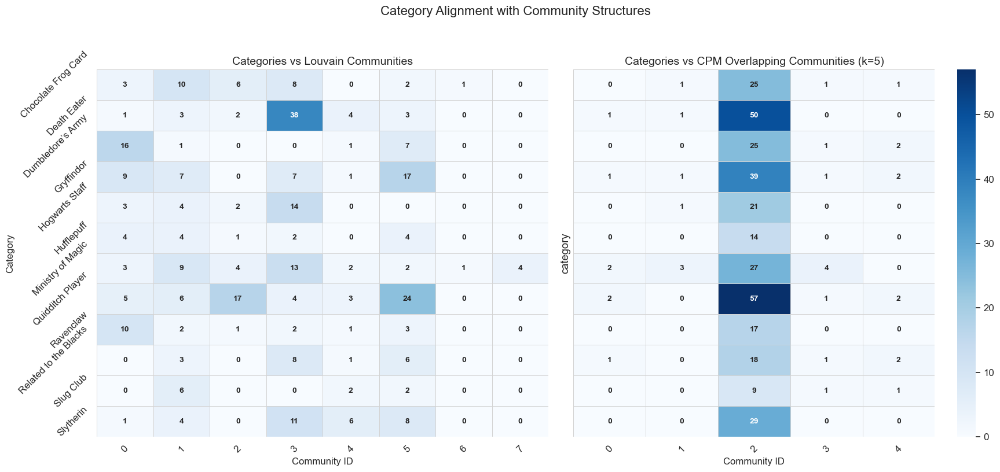

In [213]:
plot_side_by_side(
    conf_louvain,
    conf_cpm,
    title_louvain="Categories vs Louvain Communities",
    title_cpm="Categories vs CPM Overlapping Communities (k=5)"
)


In [214]:
import numpy as np
import matplotlib.pyplot as plt

def community_overlap_matrix(part_i, part_j):
    """
    Compute overlap matrix between two partitions.
    """
    overlap = np.zeros((len(part_i), len(part_j)), dtype=int)
    
    for i, comm_i in enumerate(part_i):
        for j, comm_j in enumerate(part_j):
            overlap[i, j] = len(comm_i & comm_j)

    return overlap


def plot_community_evolution_with_sizes(part_i, part_j, book_i, book_j):
    """
    Draw evolution diagram for Book i → Book j:
    - Each community displayed with size
    - Flows scaled by overlap between communities
    """
    overlap = community_overlap_matrix(part_i, part_j)
    max_overlap = overlap.max() if overlap.max() > 0 else 1

    fig, ax = plt.subplots(figsize=(12, 6))

    # Vertical positions
    left_y = np.linspace(0, 1, len(part_i))
    right_y = np.linspace(0, 1, len(part_j))

    # --- Left communities (Book i) ---
    for idx, y in enumerate(left_y):
        ax.text(
            0.05, y,
            f"C{idx} (n={len(part_i[idx])})",
            ha="left", va="center", fontsize=10
        )
        ax.scatter(0.02, y, s=80, color="tab:blue")

    # --- Right communities (Book j) ---
    for idx, y in enumerate(right_y):
        ax.text(
            0.95, y,
            f"C{idx} (n={len(part_j[idx])})",
            ha="right", va="center", fontsize=10
        )
        ax.scatter(0.98, y, s=80, color="tab:green")

    # --- Flows ---
    for i in range(len(part_i)):
        for j in range(len(part_j)):
            if overlap[i, j] > 0:
                ax.plot(
                    [0.08, 0.92],
                    [left_y[i], right_y[j]],
                    linewidth=1.5 + 5 * (overlap[i, j] / max_overlap),
                    alpha=0.5,
                    color="royalblue"
                )

    ax.set_title(f"Community Evolution: Book {book_i} → Book {book_j}", fontsize=14)
    ax.axis("off")
    plt.show()


def plot_all_evolutions_with_sizes(graph_gen, method="louvain"):
    """
    Plot evolution diagrams for Book 1→2, 2→3, ..., 6→7.
    """
    for book in range(1, 7):
        G_i = graph_gen.get_graph(book)
        G_j = graph_gen.get_graph(book + 1)

        # Choose method
        if method == "louvain":
            part_i = get_louvain_partition(G_i)
            part_j = get_louvain_partition(G_j)
        elif method == "greedy":
            part_i = greedy_communities(G_i)
            part_j = greedy_communities(G_j)
        else:
            raise ValueError("Unknown method")

        plot_community_evolution_with_sizes(part_i, part_j, book, book + 1)


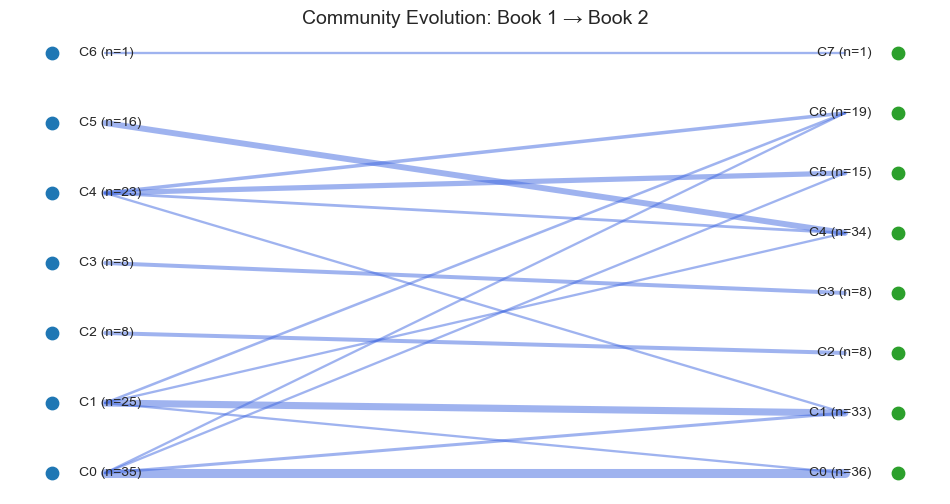

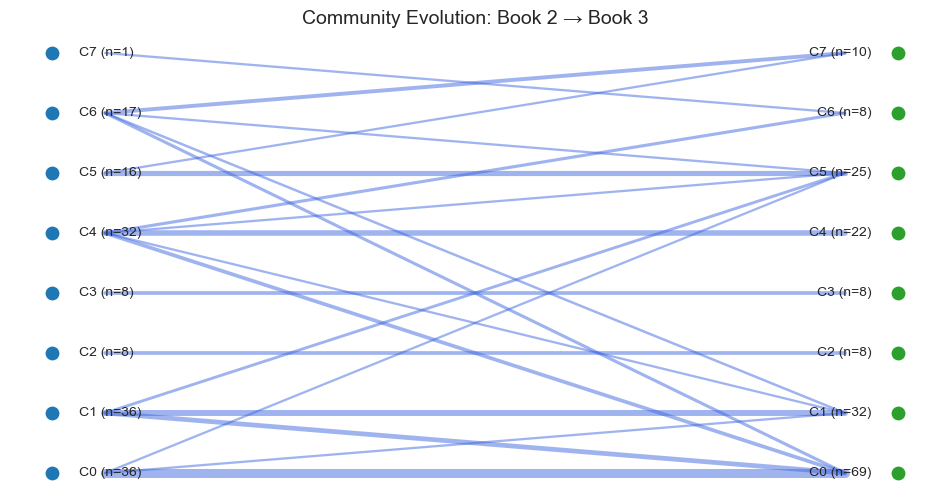

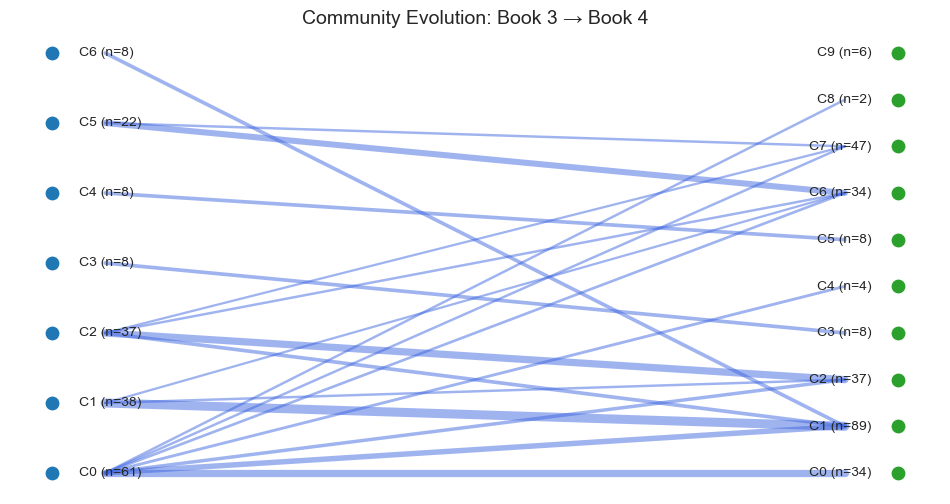

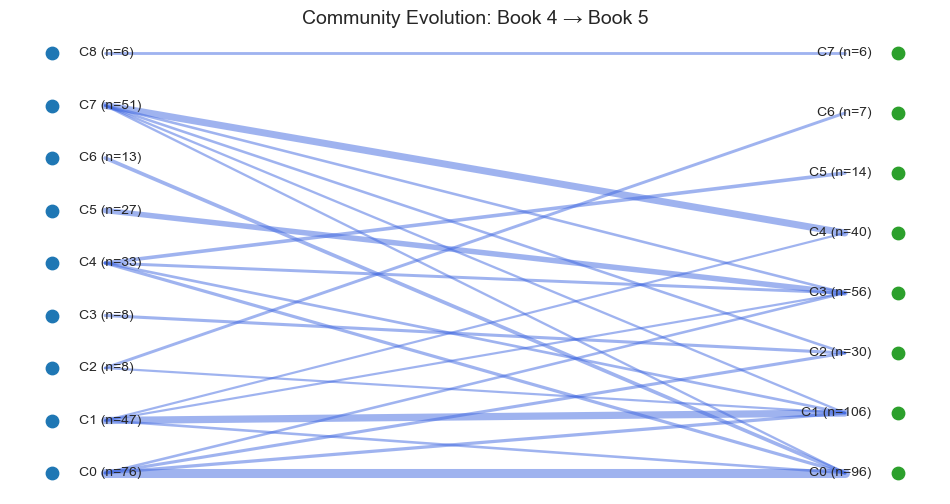

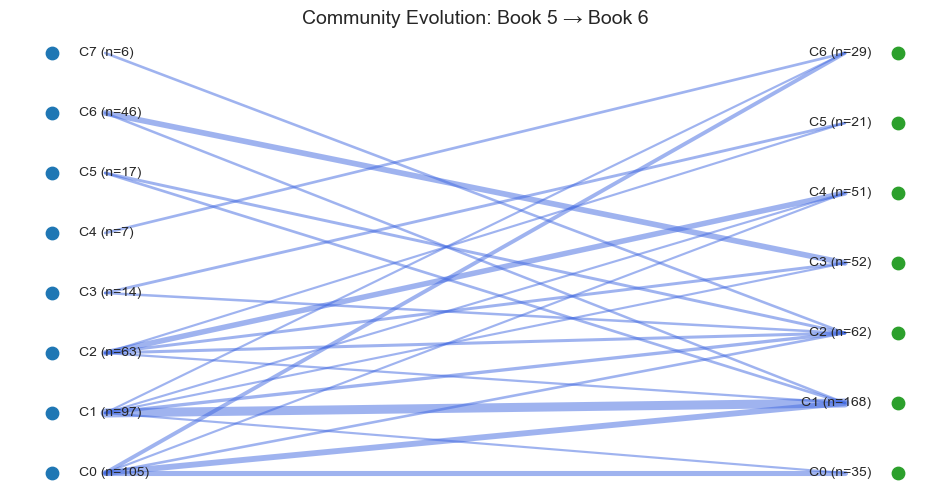

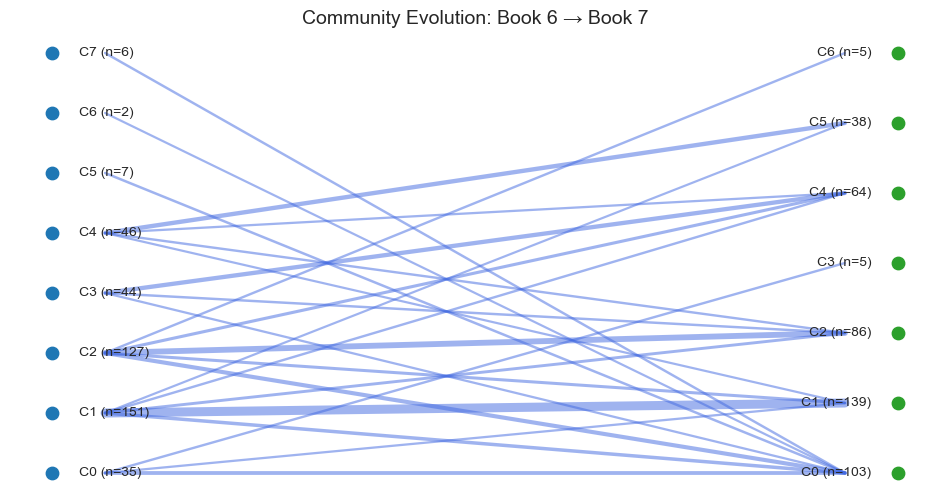

In [215]:
plot_all_evolutions_with_sizes(graph_gen, method="louvain")


In [216]:
import numpy as np
import matplotlib.pyplot as plt

def match_communities(prev_partition, next_partition):
    """
    Match communities between books by maximum overlap.
    Returns a mapping: new_index -> old_index
    """
    overlap = np.zeros((len(prev_partition), len(next_partition)))

    for i, c_prev in enumerate(prev_partition):
        for j, c_next in enumerate(next_partition):
            overlap[i, j] = len(c_prev & c_next)

    # Assign next_partition communities to the previous ones
    mapping = {}
    used_prev = set()

    for j in range(len(next_partition)):
        # find previous community with max overlap
        i_best = np.argmax(overlap[:, j])
        if overlap[i_best, j] > 0 and i_best not in used_prev:
            mapping[j] = i_best
            used_prev.add(i_best)
        else:
            # if no good match, it's a new community
            mapping[j] = None

    return mapping


def build_community_trajectories(graph_gen, method="louvain"):
    """
    For each book, detect communities and match them over time
    to build trajectories of community size over books.
    """
    partitions = []

    # 1. Detect communities in all books
    for book in range(1, 8):
        G_book = graph_gen.get_graph(book)

        if method == "louvain":
            part = get_louvain_partition(G_book)
        else:
            part = greedy_communities(G_book)

        partitions.append(part)

    # 2. Initialize trajectories using book 1
    trajectories = {i: [len(partitions[0][i])] for i in range(len(partitions[0]))}
    next_available_id = len(trajectories)

    # 3. Process books 2–7
    for t in range(1, 7):
        prev = partitions[t-1]
        curr = partitions[t]

        mapping = match_communities(prev, curr)

        # Prepare all existing trajectories for this step
        for k in trajectories:
            trajectories[k].append(0)  # default if not matched

        for j, i_prev in mapping.items():
            size = len(curr[j])
            if i_prev is not None:
                # continue an old community
                trajectories[i_prev][-1] = size
            else:
                # new community → create new trajectory
                trajectories[next_available_id] = [0]*t + [size]
                next_available_id += 1

    return trajectories


def plot_community_trajectories(graph_gen, method="louvain"):
    """
    Draw the final plot: each community gets a colored line,
    x-axis = books (1–7), y-axis = community size.
    """
    trajectories = build_community_trajectories(graph_gen, method)

    plt.figure(figsize=(12, 6))
    books = np.arange(1, 8)

    cmap = plt.cm.get_cmap("tab20", len(trajectories))

    for idx, (cid, values) in enumerate(trajectories.items()):
        plt.plot(
            books,
            values,
            marker="o",
            linewidth=2,
            color=cmap(idx),
            label=f"Comm {cid}"
        )

    plt.xlabel("Book")
    plt.ylabel("Community Size")
    plt.title(f"Community Evolution Over Time ({method})")
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper left', bbox_to_anchor=(1,1))
    plt.tight_layout()
    plt.show()


/var/folders/7b/gg3rf9zj28bfyjwgyw4z4xhw0000gq/T/ipykernel_9920/392213444.py:88: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20", len(trajectories))


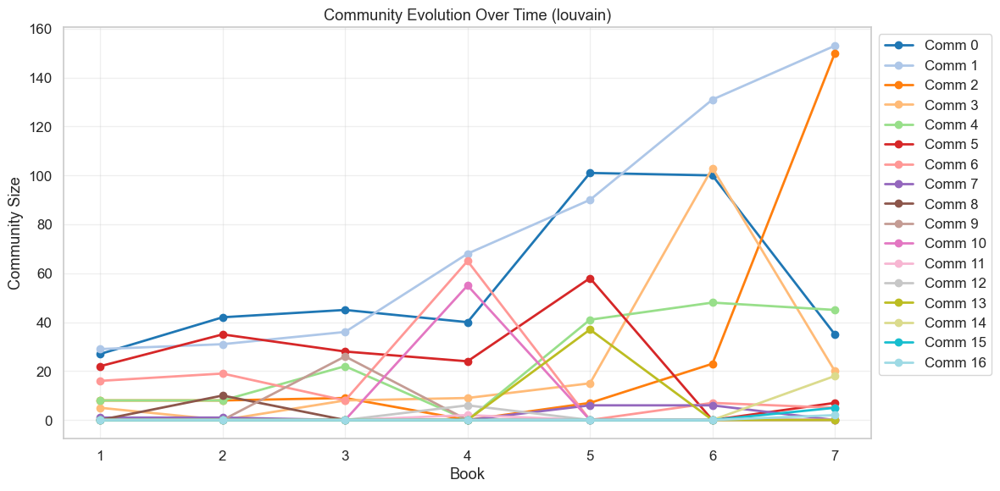

In [217]:
plot_community_trajectories(graph_gen, method="louvain")


In [224]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import math
import seaborn as sns

class NetworkAnalysis:

    # ------------------------------------------------------------------
    # BASIC INFO
    # ------------------------------------------------------------------
    @staticmethod
    def basic_info(G):
        return {
            "num_nodes": G.number_of_nodes(),
            "num_edges": G.number_of_edges(),
        }

    # ------------------------------------------------------------------
    # DEGREE DISTRIBUTION
    # ------------------------------------------------------------------
    @staticmethod
    def degree_distribution(G):
        degrees = np.array([deg for _, deg in G.degree()])
        unique_deg, counts = np.unique(degrees, return_counts=True)
        pmf = counts / counts.sum()
        sorted_deg = np.sort(degrees)
        ccdf = 1.0 - np.arange(1, len(sorted_deg) + 1) / len(sorted_deg)

        return {
            "degrees": degrees,
            "unique_deg": unique_deg,
            "pmf": pmf,
            "sorted_deg": sorted_deg,
            "ccdf": ccdf,
            "average_degree": degrees.mean(),
            "max_degree": degrees.max(),
            "min_degree": degrees.min(),
        }

    # ------------------------------------------------------------------
    # CLUSTERING
    # ------------------------------------------------------------------
    @staticmethod
    def clustering_metrics(G):
        avg_clust = nx.average_clustering(G)
        local_clust = nx.clustering(G)
        return {
            "average_clustering": avg_clust,
            "local_clustering": local_clust,
        }

    # ------------------------------------------------------------------
    # PATH LENGTH & DIAMETER
    # ------------------------------------------------------------------
    @staticmethod
    def path_metrics(G):
        if nx.is_connected(G):
            avg_path = nx.average_shortest_path_length(G)
            diameter = nx.diameter(G)
        else:
            giant = max(nx.connected_components(G), key=len)
            sg = G.subgraph(giant)
            avg_path = nx.average_shortest_path_length(sg)
            diameter = nx.diameter(sg)

        return {
            "average_path_length": avg_path,
            "diameter": diameter,
        }

    # ------------------------------------------------------------------
    # DENSITY
    # ------------------------------------------------------------------
    @staticmethod
    def density(G):
        return nx.density(G)

    # ------------------------------------------------------------------
    # CENTRALITY
    # ------------------------------------------------------------------
    @staticmethod
    def centralities(G):
        return {
            "degree_centrality": nx.degree_centrality(G),
            "betweenness_centrality": nx.betweenness_centrality(G),
            "closeness_centrality": nx.closeness_centrality(G),
        }

    # ------------------------------------------------------------------
    # SMALL-WORLD PROPERTY
    # ------------------------------------------------------------------
    @staticmethod
    def small_world_property(N, avg_deg, observed_avg_path):
        if avg_deg <= 1:
            return False  # can't take log or too sparse
        expected_d = math.log(N) / math.log(avg_deg)
        rel_error = abs(observed_avg_path - expected_d) / expected_d
        return rel_error < 0.30

    # ------------------------------------------------------------------
    # GLOBAL + PER-NODE METRICS
    # ------------------------------------------------------------------
    @staticmethod
    def compute_all(G):
        basic = NetworkAnalysis.basic_info(G)
        dist = NetworkAnalysis.degree_distribution(G)
        clust = NetworkAnalysis.clustering_metrics(G)
        paths = NetworkAnalysis.path_metrics(G)
        central = NetworkAnalysis.centralities(G)

        is_conn = nx.is_connected(G)
        largest_comp = len(max(nx.connected_components(G), key=len))
        assortativity = nx.degree_assortativity_coefficient(G)

        N = basic["num_nodes"]
        avg_deg = dist["average_degree"]
        avg_path = paths["average_path_length"]

        small_world = NetworkAnalysis.small_world_property(N, avg_deg, avg_path)

        global_metrics = {
            "num_nodes": N,
            "num_edges": basic["num_edges"],
            "average_degree": avg_deg,
            "max_degree": dist["max_degree"],
            "min_degree": dist["min_degree"],
            "average_clustering": clust["average_clustering"],
            "density": NetworkAnalysis.density(G),
            "average_path_length": avg_path,
            "diameter": paths["diameter"],
            "is_connected": is_conn,
            "largest_component_size": largest_comp,
            "degree_assortativity": assortativity,
            "small_world_property": small_world,
        }

        global_df = pd.DataFrame([global_metrics])

        node_list = list(G.nodes())
        per_node_df = pd.DataFrame({
            "node": node_list,
            "degree": [G.degree(n) for n in node_list],
            "local_clustering": [clust["local_clustering"][n] for n in node_list],
            "degree_centrality": [central["degree_centrality"][n] for n in node_list],
            "betweenness_centrality": [central["betweenness_centrality"][n] for n in node_list],
            "closeness_centrality": [central["closeness_centrality"][n] for n in node_list],
        })

        return global_df, per_node_df

    # ------------------------------------------------------------------
    # DEGREE DISTRIBUTION PLOTS
    # ------------------------------------------------------------------
    @staticmethod
    def generate_degree_distribution(G, k_min=18):
        sns.set(style="whitegrid", context="talk", palette="pastel")

        # ---------------------------------------------------------
        # DEGREE DATA
        # ---------------------------------------------------------
        degrees = np.array([deg for _, deg in G.degree()])
        unique_deg, counts = np.unique(degrees, return_counts=True)
        pmf = counts / counts.sum()
        sorted_deg = np.sort(degrees)
        ccdf = 1.0 - np.arange(1, len(sorted_deg) + 1) / len(sorted_deg)

        # ---------------------------------------------------------
        # =============== 1. POWER-LAW GAMMA ESTIMATION ===========
        # ---------------------------------------------------------
        def estimate_gamma_mle(degrees, k_min):
            ks = degrees[degrees >= k_min]
            if len(ks) == 0:
                return None
            # (Clauset-Shalizi-Newman discrete MLE)
            return 1 + len(ks) / np.sum(np.log(ks / (k_min - 0.5)))

        gamma_hat = estimate_gamma_mle(degrees, k_min)

        # ---------------------------------------------------------
        # FITTED CCDF LINE
        # CCDF(k) ~ k^{1 - gamma}
        # ---------------------------------------------------------
        if gamma_hat is not None:
            ks_fit = sorted_deg[sorted_deg >= k_min]
            ccdf_fit = (ks_fit / ks_fit[0]) ** (1 - gamma_hat) * ccdf[sorted_deg >= k_min][0]

        # ---------------------------------------------------------
        # PLOTTING
        # ---------------------------------------------------------
        fig = plt.figure(figsize=(16, 12))

        # ---------------- HISTOGRAM ----------------
        ax_hist = plt.subplot2grid((2, 2), (0, 0), colspan=2)
        bins = np.arange(min(degrees)-0.5, max(degrees)+1.5, 1)
        sns.histplot(degrees, bins=bins, kde=False, color="royalblue", alpha=0.8, ax=ax_hist)
        ax_hist.set_title("Degree Histogram")
        ax_hist.set_xlabel("Degree")
        ax_hist.set_ylabel("Count")
        ax_hist.grid(True, ls="--", lw=0.5)

        # ---------------- PMF (log-log) ----------------
        ax_pmf = plt.subplot2grid((2, 2), (1, 0))
        sns.scatterplot(x=unique_deg, y=pmf, s=50, color="steelblue", alpha=0.8, ax=ax_pmf)
        ax_pmf.set_xscale("log")
        ax_pmf.set_yscale("log")
        ax_pmf.set_title("PMF (log-log)")
        ax_pmf.set_xlabel("Degree k")
        ax_pmf.set_ylabel("P(k)")
        ax_pmf.grid(True, which="both", ls="--", lw=0.5)

        # ---------------- CCDF + POWER-LAW FIT ----------------
        ax_ccdf = plt.subplot2grid((2, 2), (1, 1))
        sns.scatterplot(x=sorted_deg, y=ccdf, s=50, color="tomato", alpha=0.8, ax=ax_ccdf, label="CCDF (data)")

        ax_ccdf.set_xscale("log")
        ax_ccdf.set_yscale("log")
        ax_ccdf.set_title("CCDF with Power-Law Fit (log-log)")
        ax_ccdf.set_xlabel("log - Degree k")
        ax_ccdf.set_ylabel("log - P(K ≥ k)")

        # Plot fitted line
        if gamma_hat is not None:
            ax_ccdf.plot(ks_fit, ccdf_fit, '--', color="black", label=f"Fit (γ={gamma_hat:.2f})", lw=2)

            # Add text
            ax_ccdf.text(0.05, 0.05, f"Estimated γ = {gamma_hat:.2f}\n(k_min = {k_min})",
                        transform=ax_ccdf.transAxes,
                        fontsize=12, bbox=dict(facecolor="white", alpha=0.7))

        ax_ccdf.legend()
        ax_ccdf.grid(True, which="both", ls="--", lw=0.5)

        # ---------------------------------------------------------
        # =============== 2. kNN(k) PLOT ===========================
        # ---------------------------------------------------------
        plt.figure(figsize=(8, 6))

        # compute knn
        knn_dict = nx.average_neighbor_degree(G)
        k_vals = []
        knn_vals = []

        for n, k in G.degree():
            k_vals.append(k)
            knn_vals.append(knn_dict[n])

        sns.scatterplot(x=k_vals, y=knn_vals, alpha=0.6)
        plt.xscale("log")
        plt.yscale("log")
        plt.xlabel("Degree k")
        plt.ylabel("Average neighbor degree k_nn(k)")
        plt.title("kNN vs Degree (assortativity detection) (log-log)")
        plt.grid(True, which="both", ls="--", lw=0.5)

        plt.show()

        print(f"\nEstimated gamma (k_min={k_min}): {gamma_hat:.3f}")
        print("Degree assortativity coefficient:", nx.degree_assortativity_coefficient(G))


In [225]:
global_df, per_node_df = NetworkAnalysis.compute_all(G)

/Users/maria/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


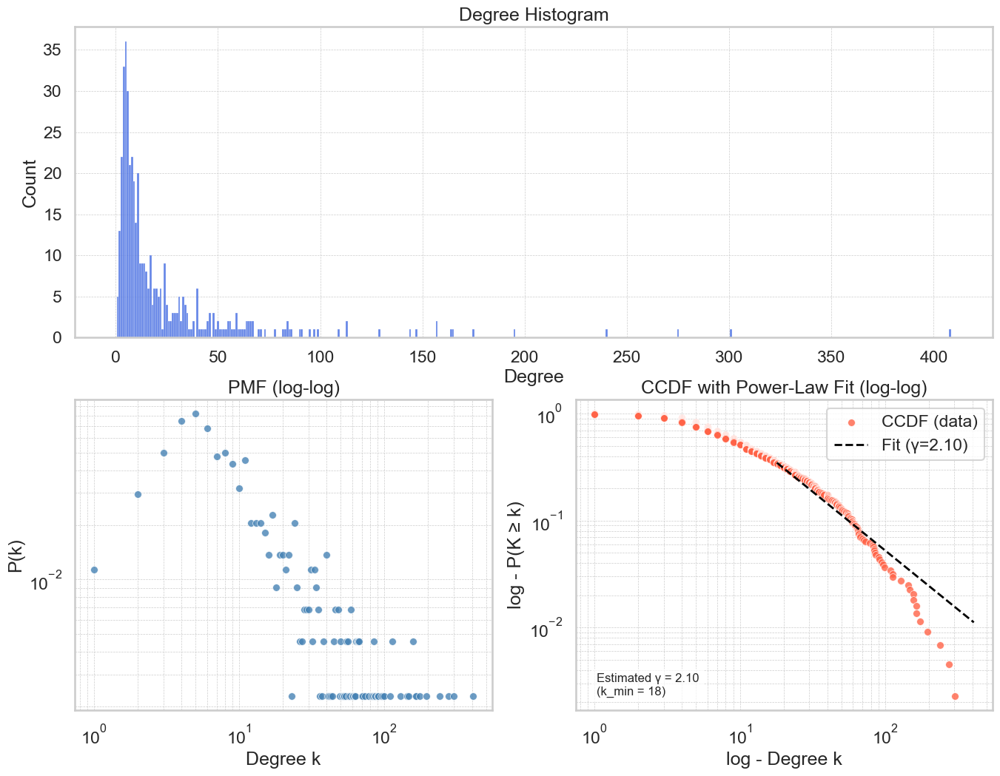

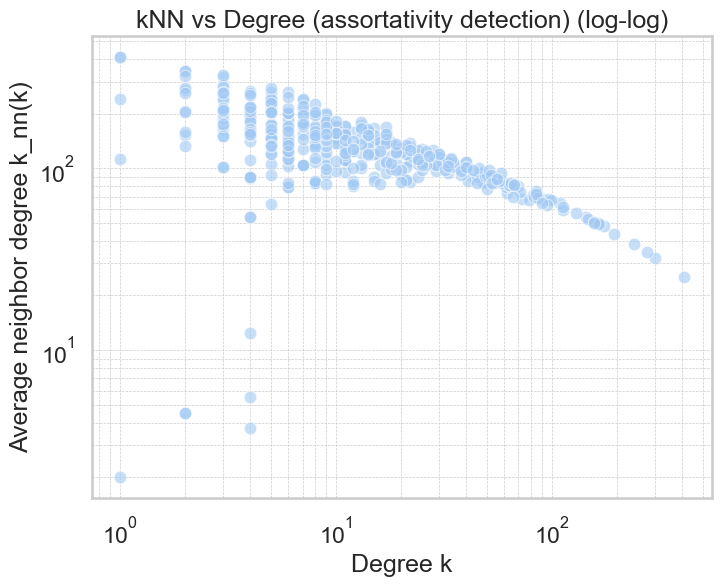


Estimated gamma (k_min=18): 2.102
Degree assortativity coefficient: -0.3281353755127066


In [226]:
NetworkAnalysis.generate_degree_distribution(G)